# Дипломски рад

**Наслов:** Анализа фактора који утичу на опредељење ученика за СТЕМ применом метода машинског учења

**Аутор:** Тијана Ђоковић

Анализа анкетних података ученика гимназија (`STEM.xlsx`) у циљу идентификације фактора повезаних са опредељењем за СТЕМ смер и развоја модела машинског учења за предвиђање тог опредељења. Рад обухвата: припрему и предобраду података, описну и статистичку анализу, методологију развоја модела, тренирање и поређење пет класификационих модела, интерпретацију резултата (значај обележја, SHAP анализа) и анализу правичности и робусности модела.

# 1. Учитавање и провера квалитета података

## 1.1. Учитавање и преглед скупа података

Учитавамо одговоре из Excel фајла (`STEM.xlsx` — без измене из кода), користимо **pandas** за табеларне податке, **seaborn/matplotlib** за графике и **scipy.stats** за тестове.

Пре моделовања (ако се додаје касније) вредно је проверити недостајуће вредности, типове колона и да ли текстуални одговори имају неочекиване варијанте (размак, различит писмо).

**Напомена о називима колона:** Након учитавања, у овом notebook-у скраћујемо само називе колона за *најчешћу оцену по предмету*, *занимљивост*, *тежину* и *корисност* предмета (исти текст као у упитнику, скраћен за прегледност). Изворни фајл `STEM.xlsx` се **не мења** — преименовање важи само за `DataFrame` у сећији испод.

In [57]:
import re

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind, chi2_contingency

sns.set_style("whitegrid")

# Уједначен изглед графика. Величине слова су подешене тако да, при убацивању
# слике ширине ~6,3 инча у рад, текст на графику испадне нешто мањи од основног
# текста (11 pt) — како је тражено у прегледу рада.
plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "legend.title_fontsize": 9,
})


In [58]:
df = pd.read_excel("STEM.xlsx")


def rename_subject_columns(kolone):
    """Скраћени називи колона за предмете (само у овом DataFrame-у; Excel остаје непромењен)."""
    preimenovanja = {}
    obrazac_ocena = re.compile(
        r"^Најчешћа оцена из наведених предмета у основној школи ми је била: (\[.+\])$"
    )
    obrazac_zanimljivost = re.compile(
        r"^Колико ти је поједини предмет био занимљив у основној школи\?\s+(\[.+\])$"
    )
    obrazac_tezina = re.compile(
        r"^Колико ти је поједини предмет био тежак у основној школи\?\s+(\[.+\])$"
    )
    obrazac_korisnost = re.compile(
        r"^Колико ти је поједини предмет био користан у основној школи\?\s+(\[.+\])$"
    )
    for kolona in kolone:
        if not isinstance(kolona, str):
            continue
        m = obrazac_ocena.match(kolona)
        if m:
            preimenovanja[kolona] = f"Најчешћа оцена {m.group(1)}"
            continue
        m = obrazac_zanimljivost.match(kolona)
        if m:
            preimenovanja[kolona] = f"Занимљив {m.group(1)}"
            continue
        m = obrazac_tezina.match(kolona)
        if m:
            preimenovanja[kolona] = f"Тежак {m.group(1)}"
            continue
        m = obrazac_korisnost.match(kolona)
        if m:
            preimenovanja[kolona] = f"Користан {m.group(1)}"
            continue
    return preimenovanja


df.rename(columns=rename_subject_columns(df.columns), inplace=True)
df.head()

,Timestamp,Пол:,Година рођења:,Похађам средњу школу:,Смер:,Разред:,Одрастао/ла сам у:,Основну школу сам завршио/ла у:,Занимање твоје мајке:,Стручна спрема твоје мајке:,...,Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Вршњаци],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Наставник],"Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Медији (телевизија, друштвене мреже, интернет, блогови итд)]",Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Склоност ка одређеној групи предмета],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Добра проходност на факултет који желим да студирам по завршетку средње школе],Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Интересовање за занимање којим желим да се бавим у будућности],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Школски психолог/педагог],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Разредни старешина],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Предметни наставник],Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Неко друго стручно лице]
0,2023-11-28 21:50:20.078,мушки,2007,„Јован Јовановић Змај“ Нови Сад,специјализовано одељење за ученике са посебним...,2.0,већем граду,већем граду,preduzetnica,завршен факултет,...,1 - нимало,2 - мало,3 - средње,5 - изразито,5 - изразито,5 - изразито,1 - нимало,1 - нимало,1 - нимало,1 - нимало
1,2023-11-28 21:52:10.331,женски,2005,„Јован Јовановић Змај“ Нови Сад,природно-математички,4.0,варошици,варошици,Radnik,завршена виша школа,...,1 - нимало,4 - доста,4 - доста,5 - изразито,5 - изразито,4 - доста,1 - нимало,2 - мало,4 - доста,1 - нимало
2,2023-11-28 21:52:16.136,женски,2005,„Јован Јовановић Змај“ Нови Сад,специјализовано одељење за ученике са посебним...,4.0,већем граду,већем граду,Lekar,завршен факултет,...,1 - нимало,1 - нимало,1 - нимало,2 - мало,4 - доста,1 - нимало,1 - нимало,1 - нимало,1 - нимало,1 - нимало
3,2023-11-28 21:52:17.193,женски,2007,„Јован Јовановић Змај“ Нови Сад,билингвално одељење (одељење у коме се део нас...,3.0,већем граду,већем граду,Diplomirani ekonomista,завршен факултет,...,3 - средње,4 - доста,2 - мало,5 - изразито,3 - средње,1 - нимало,5 - изразито,2 - мало,3 - средње,1 - нимало
4,2023-11-28 21:52:41.167,женски,2008,„Јован Јовановић Змај“ Нови Сад,природно-математички,1.0,селу,селу,Ekonomista,завршен факултет,...,1 - нимало,3 - средње,1 - нимало,3 - средње,4 - доста,4 - доста,4 - доста,5 - изразито,4 - доста,4 - доста


**Закључак:** подаци су учитани исправно — првих неколико редова показује очекивану структуру упитника. Скраћивање назива колона (Најчешћа оцена / Занимљив / Тежак / Користан + [предмет]) успешно је примењено само у овом `DataFrame`-у; изворни `STEM.xlsx` остаје непромењен.

## 1.2. Основне информације о скупу података

`info()` приказује типове и недостајуће вредности по колони; `describe()` сажетак за нумеричке колоне; `shape` број редова и колона.

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Columns: 105 entries, Timestamp to Процени колико је ко од запослених у основној школи водио са тобом разговор и саветовао те око одабира средње школе и професионалне оријентације. [Неко друго стручно лице]
dtypes: datetime64[ns](1), float64(1), int64(15), object(88)
memory usage: 856.5+ KB


In [60]:
df.describe()

,Timestamp,Година рођења:,Разред:,Најчешћа оцена [Српски језик и књижевност],Најчешћа оцена [Енглески језик],Најчешћа оцена [2. страни језик],Најчешћа оцена [Историја],Најчешћа оцена [Географија],Најчешћа оцена [Биологија],Најчешћа оцена [Математика],Најчешћа оцена [Информатика],Најчешћа оцена [Физика],Најчешћа оцена [Хемија],Најчешћа оцена [Музичка култура],Најчешћа оцена [Ликовна култура],Најчешћа оцена [Физичко васпитање],Најчешћа оцена [Техника и технологија]
count,1044,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000
mean,2023-12-19 18:51:07.355917568,2006.895594,2.381322,4.766284,4.796935,4.800766,4.818008,4.819923,4.802682,4.546935,4.909004,4.585249,4.598659,4.954023,4.954981,4.966475,4.909004
min,2023-11-28 21:50:20.078000,2005.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2023-11-29 21:27:34.893999872,2006.000000,1.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.000000,5.000000,4.000000,4.000000,5.000000,5.000000,5.000000,5.000000
50%,2023-12-14 09:02:53.044000,2007.000000,2.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
75%,2023-12-18 10:52:50.224750080,2008.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
max,2024-05-19 13:14:19.370000,2011.000000,8.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
std,NaN,1.211807,1.282004,0.549534,0.563299,0.556113,0.541137,0.554028,0.555071,0.824307,0.408861,0.771877,0.776475,0.333196,0.328984,0.306257,0.418136


In [61]:
print('Димензије:', df.shape)

Димензије: (1044, 105)


**Закључак:** скуп података има 1044 реда и 105 колона. Типови колона (`df.info()`) показују очекивану мешавину — временски печат (Timestamp), нумеричке колоне (оцене, година рођења, разред) и претежно текстуалне (object) категоријске и Ликерт колоне. `describe()` за нумеричке колоне показује да су просечне најчешће оцене високе (углавном између 4.5 и 5.0), што детаљније анализирамо у наставку рада.

### 1.2.1. Провера недостајућих вредности

Проверавамо број недостајућих (`NaN`) вредности по колони, како је најављено на почетку одељка 1.1.

In [62]:
missing_counts = df.isna().sum()
missing_cols = missing_counts[missing_counts > 0]

if len(missing_cols) == 0:
    print("Нема недостајућих вредности ни у једној од", df.shape[1], "колона.")
else:
    print(f"Број колона са недостајућим вредностима: {len(missing_cols)}")
    print(missing_cols)

Нема недостајућих вредности ни у једној од 105 колона.


**Закључак:** `isna()` провера не проналази ниједну недостајућу вредност (1044 реда × 105 колона). Треба имати у виду да `isna()` препознаје само праве `NaN`/`None` вредности — не и текстуалне уносе који су формално валидни, а семантички неисправни за своје поље. Један такав случај постоји: у колони `Колико има деце у твојој породици...` (слободан унос броја) један ред садржи `/` уместо броја. То није `NaN`, па се овде не види; уочава се и обрађује (попуњавање медијаном) тек при енкодирању, у одељку 4.5. Осим тог поља, импутација или изостављање редова/колона по основу недостајућих вредности није било потребно.

### 1.2.2. Провера неочекиваних текстуалних варијанти

Проверавамо да ли текстуалне (object) колоне садрже вишак размака на крајевима или мешано писмо (ћирилица и латиница у истом одговору), како је најављено на почетку одељка 1.1.

In [63]:
def has_whitespace(x):
    return isinstance(x, str) and x != x.strip()


def has_mixed_script(x):
    if not isinstance(x, str):
        return False
    cirilica = bool(re.search('[Ѐ-ӿ]', x))
    latinica = bool(re.search('[A-Za-z]', x))
    return cirilica and latinica


tekstualne_kolone = df.select_dtypes(include='object').columns
print(f"Број текстуалних (object) колона: {len(tekstualne_kolone)}")

kolone_sa_varijantama = {}
for col in tekstualne_kolone:
    vrednosti = df[col].dropna().unique()
    razmak = [v for v in vrednosti if has_whitespace(v)]
    mesano = [v for v in vrednosti if has_mixed_script(v)]
    if razmak or mesano:
        kolone_sa_varijantama[col] = {'вишак размака': len(razmak), 'мешано писмо': len(mesano)}

print(f"\nБрој колона са неочекиваним варијантама: {len(kolone_sa_varijantama)}")
for col, broj in kolone_sa_varijantama.items():
    print(f"  {col}: {broj}")

Број текстуалних (object) колона: 88

Број колона са неочекиваним варијантама: 4
  Занимање твоје мајке:: {'вишак размака': 92, 'мешано писмо': 1}
  Занимање твог оца:: {'вишак размака': 82, 'мешано писмо': 0}
  Зашто сте изабрали да упишите Гимназију?: {'вишак размака': 139, 'мешано писмо': 0}
  Зашто сте изабрали да упишете овај смер?: {'вишак размака': 133, 'мешано писмо': 1}


**Закључак:** неочекиване варијанте (вишак размака, мешано писмо) постоје искључиво у четири слободнотекстуалне колоне — `Занимање твоје мајке:`, `Занимање твог оца:`, `Зашто сте изабрали да упишите Гимназију?` и `Зашто сте изабрали да упишете овај смер?`. Ниједна од ових колона се не користи у даљој анализи (већ су искључене из `X` у одељку 1.4 као описне/слободнотекстуалне), тако да ове варијанте немају утицаја на резултате. Ниједна друга (категоријска или Ликерт) колона нема оваквих варијанти.

## 1.3. Провера квалитета: `Разред:`

Колона `Разред:` треба да садржи цео број (типично 1–4 за гимназију; више вредности могуће за специјализована одељења у оквиру осмогодишњих програма). Проверавамо да ли постоје нецелобројне вредности и, ако постоје, заокружујемо их на најближи цео број.

In [64]:
neispravni_razred = df[df['Разред:'] % 1 != 0]
print(f"Број редова са нецелобројном вредношћу у 'Разред:': {len(neispravni_razred)}")
print(neispravni_razred[['Разред:']])

df.loc[neispravni_razred.index, 'Разред:'] = df.loc[neispravni_razred.index, 'Разред:'].round()

print("\nВредност заокружена на најближи цео број. Расподела после исправке:")
print(df['Разред:'].value_counts().sort_index())

Број редова са нецелобројном вредношћу у 'Разред:': 1
     Разред:
775      2.1

Вредност заокружена на најближи цео број. Расподела после исправке:
Разред:
1.0    344
2.0    235
3.0    237
4.0    214
6.0      1
7.0      5
8.0      8
Name: count, dtype: int64


**Закључак:** пронађен је тачно један ред (индекс 775) са нецелобројном вредношћу `Разред: 2.1`, заокружен на најближи цео број (2). После исправке, расподела разреда је: 1 (344), 2 (235), 3 (237), 4 (214) редова, док преостали ретки редови ван опсега 1–4 (6, 7, 8) детаљно се разматрају у наредном одељку.

### 1.3.1. Провера доследности: разреди ван опсега 1–4 и година рођења

Претпостављамо да свака школа у скупу података омогућава упис ученика директно у **7. или 8. разред** (рана/специјализована одељења за надарене ученике), поред стандардних разреда 1–4. Разреди **5 и 6** не постоје ни у једном програму.

За све редове ван опсега 1–4 (без обзира на школу) проверавамо:
1. да ли је вредност разреда 7 или 8 (дозвољено) — све остало (нпр. 5, 6) је аномалија;
2. да ли се година рођења слаже са очекиваном годином рођења за тај разред (претпоставка: почетак школовања око 7. године живота; референтна школска 2023/2024. година).

In [65]:
REFERENTNA_GODINA = 2023

van_opsega = df[~df['Разред:'].isin([1, 2, 3, 4])].copy()
van_opsega['Дозвољен разред (7 или 8)'] = van_opsega['Разред:'].isin([7, 8])
van_opsega['Очекивана година рођења'] = REFERENTNA_GODINA - (van_opsega['Разред:'] + 6)
van_opsega['Одступање (год.)'] = (
    van_opsega['Година рођења:'] - van_opsega['Очекивана година рођења']
).abs()

print(van_opsega[[
    'Похађам средњу школу:', 'Разред:', 'Дозвољен разред (7 или 8)',
    'Година рођења:', 'Очекивана година рођења', 'Одступање (год.)'
]].to_string())

anomalije = van_opsega[~van_opsega['Дозвољен разред (7 или 8)'] | (van_opsega['Одступање (год.)'] > 2)]
print(f"\nБрој потврђених аномалија: {len(anomalije)}")
print(anomalije[['Похађам средњу школу:', 'Разред:', 'Година рођења:']])

               Похађам средњу школу:  Разред:  Дозвољен разред (7 или 8)  Година рођења:  Очекивана година рођења  Одступање (год.)
6    „Јован Јовановић Змај“ Нови Сад      8.0                       True            2010                   2009.0               1.0
11   „Јован Јовановић Змај“ Нови Сад      8.0                       True            2009                   2009.0               0.0
17   „Јован Јовановић Змај“ Нови Сад      7.0                       True            2010                   2010.0               0.0
55   „Јован Јовановић Змај“ Нови Сад      8.0                       True            2009                   2009.0               0.0
115  „Јован Јовановић Змај“ Нови Сад      8.0                       True            2009                   2009.0               0.0
117  „Јован Јовановић Змај“ Нови Сад      8.0                       True            2009                   2009.0               0.0
118  „Јован Јовановић Змај“ Нови Сад      7.0                       True    

**Закључак:** провера проналази тачно једну потврђену аномалију — ученик/ца Друге крагујевачке гимназије са `Разред: 6` и `Година рођења: 2005` (ни разред није у дозвољеном скупу {1,2,3,4,7,8}, нити година рођења одговара очекиваној за тај разред — одступање 6 година). Сви остали редови ван опсега 1–4 показују доследан образац (разред и година рођења се слажу за 7./8. разред).

Ову вредност **намерно остављамо непромењену** у `df`: ни `Разред:` ни `Година рођења:` не улазе у дефиницију циљне променљиве `СТЕМ` (која зависи искључиво од `Смер:`), нити се користе у било ком од статистичких тестова или корелационе матрице у наставку — тако да ова аномалија нема утицаја на резултате анализе. Пошто је реч о само једном реду од 1044, задржавамо га уз ову напомену уместо да га бришемо или коригујемо.

## 1.4. Дефинисање циљне променљиве (СТЕМ vs НЕ-СТЕМ)

Циљна променљива је **бинарна**: ученик је на једном од наведених *СТЕМ* смерава у гимназији (`1`) или није (`0`). Вредност градимо из колоне **`Смер:`** (како је у анкети), без измене изворног Excel фајла.

Листа `stem_smerovi` треба да одговара дефиницији СТЕМ-а у тексту рада; ако се дефиниција промени, мења се само ова листа и поново покрећу ћелије испод.


Пре дефинисања листе `stem_smerovi`, прегледамо све различите вредности колоне `Смер:` и њихове фреквенције — тако имамо потпун преглед свих смерова који се јављају у подацима, пре него што одлучимо који од њих улазе у СТЕМ дефиницију.

In [66]:
df['Смер:'].value_counts(dropna=False)

Смер:
општи смер                                                                            464
природно-математички                                                                  222
специјализовано одељење за ученике са посебним способностима за информатику            84
специјализовано одељење за ученике са посебним способностима за математику             62
специјализовано одељење за ученике са посебним способностима за биологију и хемију     55
билингвално одељење (одељење у коме се део наставе реализује на страном језику)        55
друштвено-језички                                                                      48
специјализовано одељење за ученике са посебним способностима за филолошке науке        29
специјализовано одељење за ученике са посебним способностима за спорт                  14
специјализовано одељење за ученике са посебним способностима за физику                 11
Name: count, dtype: int64

На основу прегледа свих 10 различитих вредности колоне `Смер:`, као СТЕМ вредности користићемо само следећих пет:

- `природно-математички`
- `специјализовано одељење за ученике са посебним способностима за информатику`
- `специјализовано одељење за ученике са посебним способностима за математику`
- `специјализовано одељење за ученике са посебним способностима за биологију и хемију`
- `специјализовано одељење за ученике са посебним способностима за физику`

Остале вредности (општи смер, билингвално одељење, друштвено-језички, филолошке науке, спорт) третирамо као НЕ-СТЕМ.

In [67]:
stem_smerovi = [
    'природно-математички',
    'специјализовано одељење за ученике са посебним способностима за информатику',
    'специјализовано одељење за ученике са посебним способностима за математику',
    'специјализовано одељење за ученике са посебним способностима за биологију и хемију',
    'специјализовано одељење за ученике са посебним способностима за физику',
]

# Колона СТЕМ: 1 = смер из листе изнад, 0 = остали смерави; NaN у Смер: третирамо као 0
df['СТЕМ'] = df['Смер:'].apply(lambda x: 1 if pd.notna(x) and x in stem_smerovi else 0)

print('Апсолутне фреквенције:')
print(df['СТЕМ'].value_counts().sort_index())
print('\nУдео (нормализовано):')
print(df['СТЕМ'].value_counts(normalize=True).round(4))

# Унапред упозорење ако у подацима има вредности смера које нису у листи (провера конзистентности)
sve_smerove = df['Смер:'].dropna().unique()
nepoznato = [s for s in sorted(sve_smerove, key=str) if s not in stem_smerovi and s is not np.nan]
print(f"\nБрој различитих 'осталих' смерава (није у stem_smerovi): {len(nepoznato)}")

Апсолутне фреквенције:
СТЕМ
0    610
1    434
Name: count, dtype: int64

Удео (нормализовано):
СТЕМ
0    0.5843
1    0.4157
Name: proportion, dtype: float64

Број различитих 'осталих' смерава (није у stem_smerovi): 5


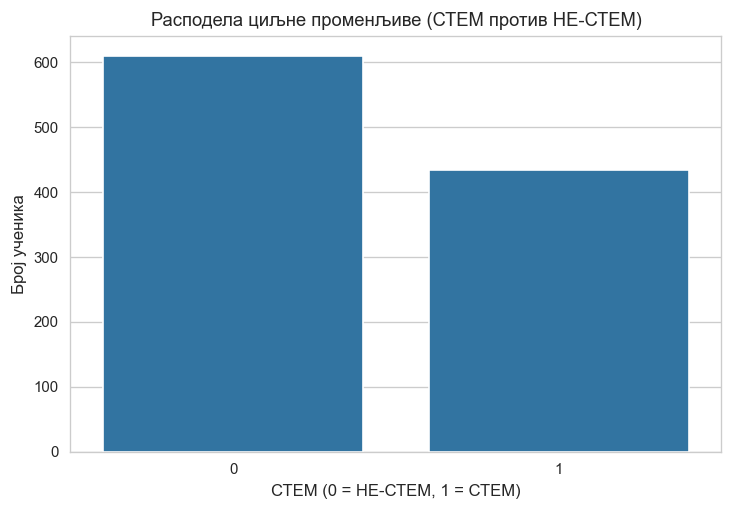

In [68]:
sns.countplot(x='СТЕМ', data=df)
plt.xlabel('СТЕМ (0 = НЕ-СТЕМ, 1 = СТЕМ)')
plt.ylabel('Број ученика')
plt.title('Расподела циљне променљиве (СТЕМ против НЕ-СТЕМ)')
plt.show()

**Закључак:** циљна променљива `СТЕМ` је успешно дефинисана на основу колоне `Смер:` — 434 ученика (41.57%) припада једном од пет наведених СТЕМ смерова, док 610 ученика (58.43%) припада осталим смеровима (НЕ-СТЕМ). Расподела је умерено небалансирана, али без екстремне доминације једне класе, што је прихватљиво за даље статистичко тестирање и моделовање.

### 1.4.1. Искључивање колона за даље моделовање (описни / слободни текст)

Следеће колоне су **описног карактера** (слободан текст или сиров временски печат) и у овом облику нису погодне за директан унос у класичне предиктивне моделе без NLP или додатног кодирања. У наставку их избацујемо из матрице обележја `X`.

- `Timestamp`
- `Занимање твоје мајке:`, `Занимање твог оца:`
- `Зашто сте изабрали да упишите Гимназију?`, `Зашто сте изабрали да упишете овај смер?`

Циљна променљива остаје у `y` (колона `СТЕМ` у `df`).


In [69]:
cols_to_drop = [
    'Timestamp',
    'Занимање твоје мајке:',
    'Занимање твог оца:',
    'Зашто сте изабрали да упишите Гимназију?',
    'Зашто сте изабрали да упишете овај смер?',
]
X = df.drop(columns=cols_to_drop)
y = df['СТЕМ']

print('Колоне у X (укључујући СТЕМ за EDA графике са hue):')
print(X.columns.tolist())

Колоне у X (укључујући СТЕМ за EDA графике са hue):
['Пол:', 'Година рођења:', 'Похађам средњу школу:', 'Смер:', 'Разред:', 'Одрастао/ла сам у:', 'Основну школу сам завршио/ла у:', 'Стручна спрема твоје мајке:', 'Стручна спрема твог оца:', 'Колико има деце у твојој породици, рачунајући и тебе (упиши број):', 'Какав си био/ла ђак у основној школи?', 'Најомиљенији предмет:', 'Други омиљени предмет (омиљени предмет, мање омиљени од претходног):', 'Трећи омиљени предмет (омиљени предмет, мање омиљени од претходна два):', 'Тежак [Српски језик и књижевност]', 'Тежак [Енглески језик]', 'Тежак [2. страни језик]', 'Тежак [Историја]', 'Тежак [Географија]', 'Тежак [Биологија]', 'Тежак [Математика]', 'Тежак [Информатика]', 'Тежак [Физика]', 'Тежак [Хемија]', 'Тежак [Музичка култура]', 'Тежак [Ликовна култура]', 'Тежак [Физичко васпитање]', 'Тежак [Техника и технологија]', 'Користан [Српски језик и књижевност]', 'Користан [Енглески језик]', 'Користан [2. страни језик]', 'Користан [Историја]', 'Кори

In [70]:
# Заједничке ознаке за СТЕМ/НЕ-СТЕМ групу, коришћене у графицима и табелама у наставку
STEM_LABELS = {0: 'НЕ-СТЕМ', 1: 'СТЕМ', 0.0: 'НЕ-СТЕМ', 1.0: 'СТЕМ'}

**Закључак:** уклоњено је пет описних/слободнотекстуалних колона (`Timestamp` и четири колоне са слободним текстом) из матрице обележја `X`, која сада има 101 колону (укључујући циљну променљиву `СТЕМ`, задржану овде ради EDA графика у наредном поглављу). Ове колоне остају недирнуте у `df` и биће поново размотрене, заједно са додатним административним колонама, у одељку 4.1.

# 2. Описна анализа

## 2.1. Анализа неких предмета који припадају СТЕМ областима

Поређење расподеле најчешћих оцена из математике, физике и (као референца) српског језика. Кутијасти дијаграм показује медијан, квартиле и изласке.

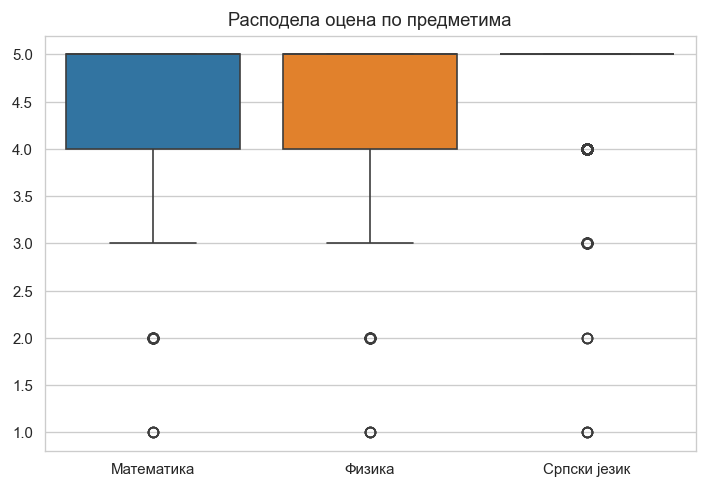

In [71]:
data = X[[
    'Најчешћа оцена [Математика]',
    'Најчешћа оцена [Физика]',
    'Најчешћа оцена [Српски језик и књижевност]',
]]

sns.boxplot(data=data)

plt.xticks(
    ticks=[0, 1, 2],
    labels=['Математика', 'Физика', 'Српски језик']
)

plt.title('Расподела оцена по предметима')
plt.show()

**Закључак:** медијана оцене је 5 за сва три предмета (види `describe()` из одељка 1.2), али распон је шири код математике и физике — доња граница (25. перцентил) им је 4, за разлику од српског језика где је и доња граница већ 5. То се слаже и са већим стандардним девијацијама за математику (≈0.82) и физику (≈0.77) у односу на српски (≈0.55): оцене из математике и физике варирају више међу ученицима, док су оцене из српског готово увек максималне.

## 2.2. Анализа категоријских обележја

Фреквенције и графикони за изабране категоријске променљиве (нпр. пол, величина места одрастања).

In [72]:
X['Пол:'].value_counts()

Пол:
женски    715
мушки     329
Name: count, dtype: int64

In [73]:
X['Одрастао/ла сам у:'].value_counts()

Одрастао/ла сам у:
већем граду    712
селу           139
мањем граду     98
варошици        95
Name: count, dtype: int64

**Закључак:** узорак је родно небалансиран — 715 ученица (68.5%) наспрам 329 ученика (31.5%). По месту одрастања, знатна већина (712, односно 68.2%) одрасла је у већем граду, док су село (139, 13.3%), мањи град (98, 9.4%) и варошица (95, 9.1%) знатно мање заступљени. Ова структура узорка треба да се има у виду приликом тумачења каснијих резултата — узорак није равномерно распоређен ни по полу ни по степену урбанизације места одрастања.

## 2.3. Однос категоријских обележја и СТЕМ опредељења

Упоредни приказ (hue = СТЕМ) помаже да се види да ли се расподела категорије разликује између СТЕМ и НЕ-СТЕМ групе.

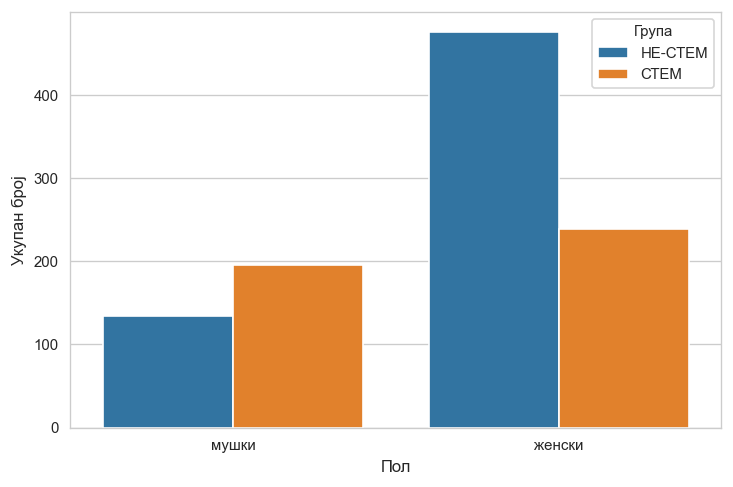

In [74]:
X_plot = X.copy()
X_plot['СТЕМ'] = X_plot['СТЕМ'].map(STEM_LABELS)

sns.countplot(x='Пол:', hue='СТЕМ', data=X_plot, hue_order=['НЕ-СТЕМ', 'СТЕМ'])
plt.xlabel('Пол')
plt.ylabel('Укупан број')
plt.legend(title='Група')
plt.show()


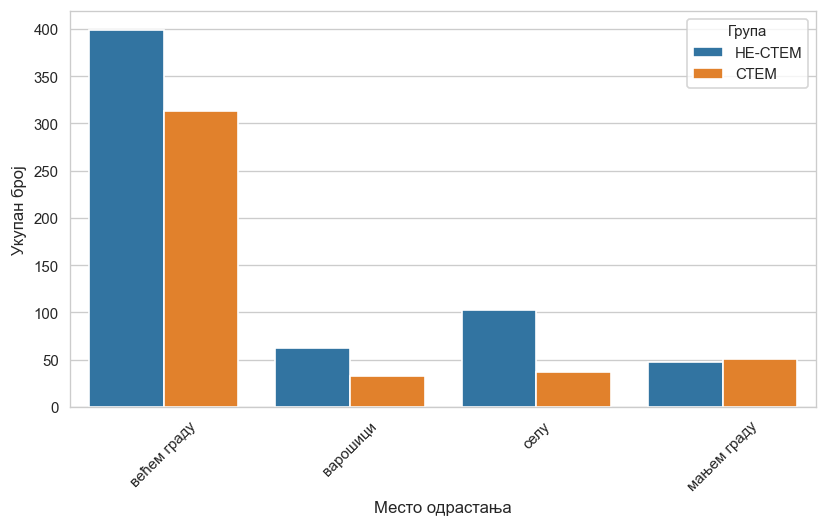

In [75]:
X_plot = X.copy()
X_plot['СТЕМ'] = X_plot['СТЕМ'].map(STEM_LABELS)

sns.countplot(x='Одрастао/ла сам у:', hue='СТЕМ', data=X_plot, hue_order=['НЕ-СТЕМ', 'СТЕМ'])
plt.xticks(rotation=45)
plt.xlabel('Место одрастања')
plt.ylabel('Укупан број')
plt.legend(title='Група')
plt.tight_layout()
plt.show()


**Закључак:** упоредни приказ (hue = СТЕМ) визуелно указује на разлике у СТЕМ опредељењу и по полу и по месту одрастања — међу мушким ученицима СТЕМ се чини пропорционално заступљенијим него међу женским, а међу ученицима из већих градова пропорционално заступљенијим него међу онима из села. Ова запажања се формално тестирају χ² тестовима у одељцима 3.5 и 3.6.

## 2.4. Стубичасти дијаграм (просеци)

Поређење **просечних** најчешћих оцена из математике, физике и српског језика између групе СТЕМ и НЕ-СТЕМ (`groupby` + `plot(kind='bar')`).

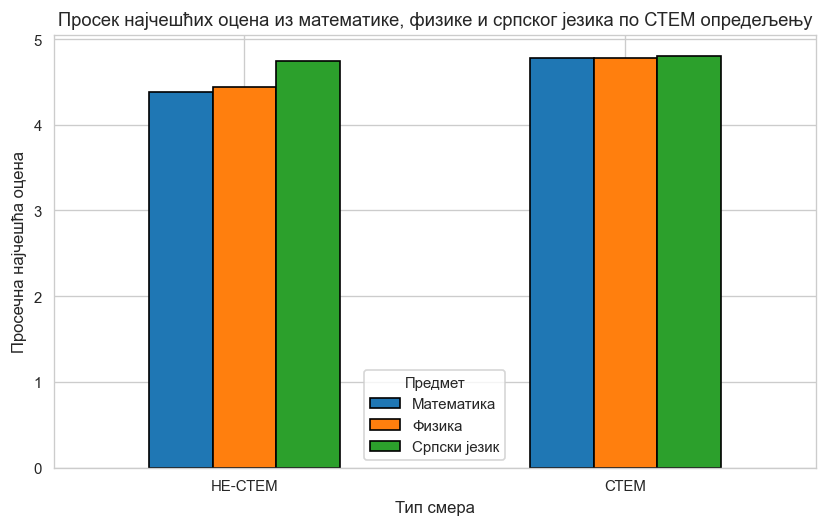

In [76]:
grade_cols_mean = [
    'Најчешћа оцена [Математика]',
    'Најчешћа оцена [Физика]',
    'Најчешћа оцена [Српски језик и књижевност]',
]
plot_df = X.groupby('СТЕМ')[grade_cols_mean].mean()
plot_df.columns = ['Математика', 'Физика', 'Српски језик']
plot_df.index = [STEM_LABELS.get(k, k) for k in plot_df.index]
ax = plot_df.plot(kind='bar', rot=0, figsize=(7, 4.5), edgecolor='black')
plt.ylabel('Просечна најчешћа оцена')
plt.xlabel('Тип смера')
plt.title('Просек најчешћих оцена из математике, физике и српског језика по СТЕМ опредељењу')
plt.legend(title='Предмет')
plt.tight_layout()
plt.show()

**Закључак:** стубичасти дијаграм показује да СТЕМ ученици у просеку остварују веће оцене из математике и физике него НЕ-СТЕМ ученици, док су просечне оцене из српског језика визуелно врло сличне за обе групе. Ова разлика за математику и физику формално се потврђује Welch t-тестовима у одељку 3.1.

In [77]:
def likert_to_number(x):
    """'1 - нимало' или већ int 1–5 → број за просек."""
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, np.integer)):
        return int(x)
    if isinstance(x, float) and x == int(x):
        return int(x)
    s = str(x).strip()
    if not s:
        return np.nan
    return int(s.split('-')[0].strip())

## 2.5. Корелациона матрица

### 2.5.1. Избор колона за ову матрицу

Користимо само: **СТЕМ**, најчешће оцене из **математике**, **физике** и **информатике**, као и Ликерт процене **занимљивости** и **тежине** за **математику** и **физику** (списак је експлицитно у наредној ћелији).

Ликерт ставови се претварају у бројеве (види ћелију испод); затим се за изабране колоне рачуна **Спирманова (Spearman) корелација ранга**, а не Пирсонова: већина укључених променљивих је **ординална** (Ликерт скале 1–5, оцене), а Спирманова корелација претпоставља само монотону везу међу рангирањем вредности, без претпоставке да су размаци између категорија једнаки (што Пирсонова корелација имплицитно претпоставља). За СТЕМ (бинарна) насупрот осталим, Спирманова корелација и даље даје валидну меру повезаности. Матрица је илустративна — за закључке о узрочности потребна је додатна анализа.

Питања са одговорима у облику *„1 - нимало“*, *„2 - мало“*, … мапирамо на цео број (1–5) преузимањем дела пре цртице (помоћу `likert_to_number` дефинисане изнад). То омогућава корелацију и топлотну мапу; **није** исто што и формално моделирање као континуиране променљиве, али је уобичајен корак у описној анализи.

In [78]:
likert_cols = [
    col
    for col in X.columns
    if 'Процени' in col
    or col.startswith('Занимљив ')
    or col.startswith('Тежак ')
    or col.startswith('Користан ')
]

for col in likert_cols:
    X[col] = X[col].apply(likert_to_number)

In [79]:
selected_columns = [
    'СТЕМ',
    'Најчешћа оцена [Математика]',
    'Најчешћа оцена [Физика]',
    'Најчешћа оцена [Информатика]',
    'Занимљив [Математика]',
    'Занимљив [Физика]',
    'Тежак [Математика]',
    'Тежак [Физика]',
]

corr = X[selected_columns].corr(method='spearman')

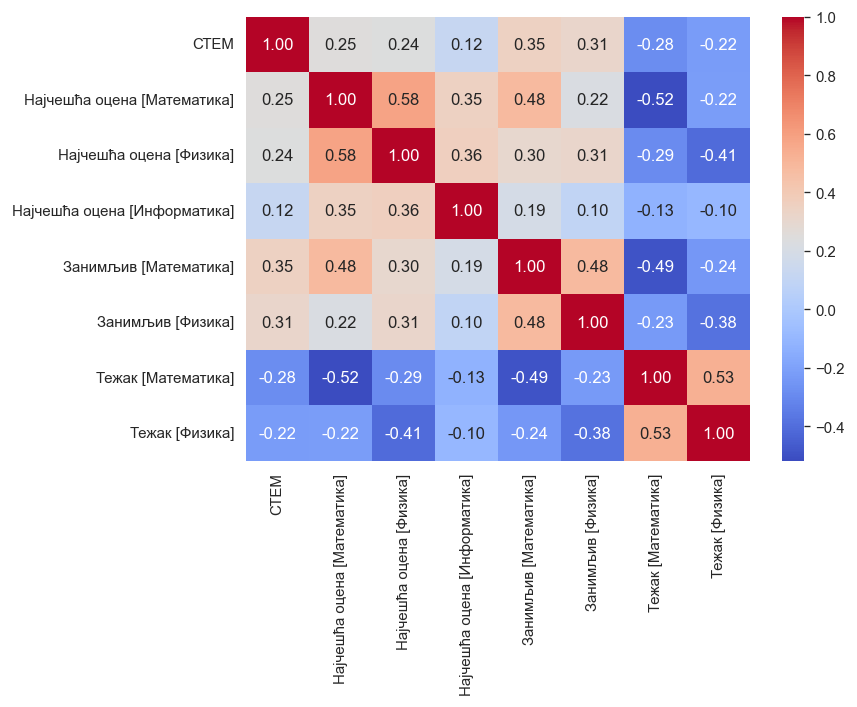

In [80]:
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.tight_layout()
plt.show()

**Закључак:** топлотна мапа показује да су СТЕМ опредељење и перципирана занимљивост математике (ρ=0.35) и физике (ρ=0.31) најјаче позитивно повезани показатељи у овом избору, док су перципирана тежина ова два предмета негативно повезана са СТЕМ опредељењем (ρ=-0.28 за математику, ρ=-0.22 за физику) — ученици који сматрају ове предмете тежим ређе бирају СТЕМ смер. Најчешћа оцена из математике и физике показује слабију, али и даље позитивну повезаност (ρ=0.25 и ρ=0.24). Међу самим предикторима, најизраженија је негативна веза између оцене и перципиране тежине математике (ρ=-0.52) — очекивано, ученици који предмет доживљавају као тежак у просеку имају ниже оцене.

# 3. Статистички тестови

У овом одељку формално тестирамо да ли постоји статистички значајна разлика или повезаност између СТЕМ и НЕ-СТЕМ групе, за показатеље описане и приказане графички у наставку. Користе се два типа тестова:

- **t-тест за независне узорке** (Welch-ова варијанта, `equal_var=False`): за поређење просечне вредности нумеричке/ординалне променљиве (оцене, тежина, занимљивост, корисност) између две групе. Смер хипотезе (једнострано или двострано) наведен је уз сваки тест; тамо где се истовремено тестира више предмета за исту хипотезу, примењена је **Бонферонијева корекција** прага значајности.
- **χ² тест независности**: за две категоријске променљиве (нпр. пол × СТЕМ, место одрастања × СТЕМ) на контингенцијској табели, уз проверу претпоставке о минималним очекиваним фреквенцијама (све ≥ 5).

## 3.1. Оцене из СТЕМ предмета: да ли СТЕМ ученици имају боље оцене?

Поредимо **најчешће оцене** из типичних СТЕМ предмета у основној школи (математика, физика, информатика, хемија, биологија — само колоне које постоје у `X`) између група **СТЕМ** и **НЕ-СТЕМ**. Приказујемо **просек** по групи и **Welch t-тест** (`equal_var=False`) са `alternative='greater'`: хипотеза да је просек у СТЕМ групи **већи** од НЕ-СТЕМ.

Пошто се овде спроводи **пет** t-тестова над истом врстом хипотезе (различити предмети), примењена је **Бонферонијева корекција** (прилагођени праг значајности α/5) како би се контролисала вероватноћа лажно позитивног резултата услед вишеструког тестирања. Резултат: сви тестови остају статистички значајни и након корекције.

Ово поређење је **описно** у смислу групе које се пореде — не значи да је избор смера *узрок* разлике у оценама.

Просечна најчешћа оцена по групи (СТЕМ предмети):
         Математика  Физика  Информатика  Хемија  Биологија
СТЕМ                                                       
НЕ-СТЕМ       4.382   4.444        4.882   4.479      4.762
СТЕМ          4.779   4.783        4.947   4.767      4.859


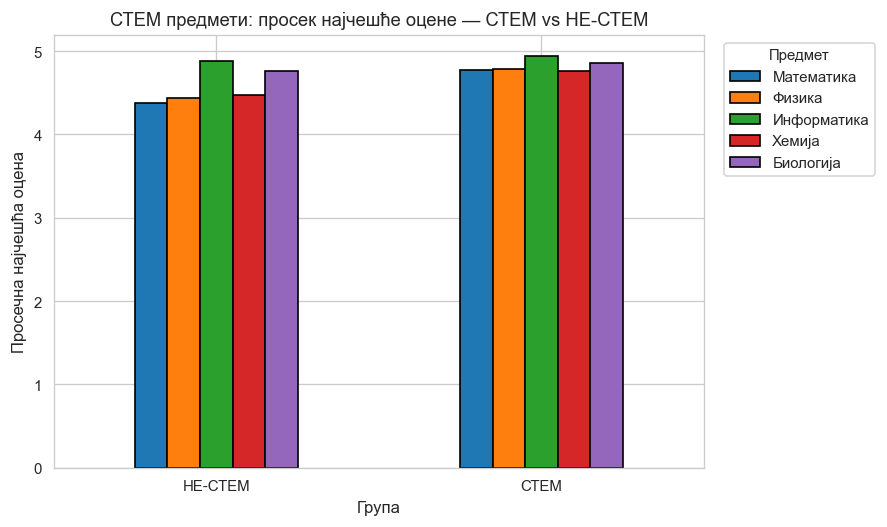

Welch t-тест, једнострано СТЕМ > НЕ-СТЕМ (scipy: alternative='greater'):
Бонферонијева корекција за 5 тестова: прилагођени праг значајности = 0.05/5 = 0.0100

  Математика: t=8.437, p=0.00000 (n_stem=434, n_non=610, mean_stem=4.779, mean_non=4.382) -> значајно након Бонферонијеве корекције: да
  Физика: t=7.577, p=0.00000 (n_stem=434, n_non=610, mean_stem=4.783, mean_non=4.444) -> значајно након Бонферонијеве корекције: да
  Информатика: t=2.583, p=0.00497 (n_stem=434, n_non=610, mean_stem=4.947, mean_non=4.882) -> значајно након Бонферонијеве корекције: да
  Хемија: t=6.309, p=0.00000 (n_stem=434, n_non=610, mean_stem=4.767, mean_non=4.479) -> значајно након Бонферонијеве корекције: да
  Биологија: t=2.879, p=0.00203 (n_stem=434, n_non=610, mean_stem=4.859, mean_non=4.762) -> значајно након Бонферонијеве корекције: да


In [81]:
STEM_PREDMET_OCENE = [
    'Најчешћа оцена [Математика]',
    'Најчешћа оцена [Физика]',
    'Најчешћа оцена [Информатика]',
    'Најчешћа оцена [Хемија]',
    'Најчешћа оцена [Биологија]',
]
stem_grade_cols = [c for c in STEM_PREDMET_OCENE if c in X.columns]

means_stem_pred = (
    X.groupby('СТЕМ')[stem_grade_cols]
    .mean()
    .round(3)
    .rename(index=lambda k: STEM_LABELS.get(k, k))
)
means_stem_pred.columns = [
    c.replace('Најчешћа оцена [', '').replace(']', '') for c in means_stem_pred.columns
]
print('Просечна најчешћа оцена по групи (СТЕМ предмети):')
print(means_stem_pred)

plot_stem = means_stem_pred.copy()
ax = plot_stem.plot(kind='bar', rot=0, figsize=(7.5, 4.5), edgecolor='black')
plt.ylabel('Просечна најчешћа оцена')
plt.xlabel('Група')
plt.title('СТЕМ предмети: просек најчешће оцене — СТЕМ vs НЕ-СТЕМ')
plt.legend(title='Предмет', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

ALPHA = 0.05
m = len(stem_grade_cols)
alpha_bonferroni = ALPHA / m

print("Welch t-тест, једнострано СТЕМ > НЕ-СТЕМ (scipy: alternative='greater'):")
print(f"Бонферонијева корекција за {m} тестова: прилагођени праг значајности = {ALPHA}/{m} = {alpha_bonferroni:.4f}\n")
for col in stem_grade_cols:
    a = pd.to_numeric(X.loc[X['СТЕМ'] == 1, col], errors='coerce').dropna()
    b = pd.to_numeric(X.loc[X['СТЕМ'] == 0, col], errors='coerce').dropna()
    res = ttest_ind(a, b, equal_var=False, alternative='greater')
    predmet = col.replace('Најчешћа оцена [', '').replace(']', '')
    znacajno_bonferroni = 'да' if res.pvalue < alpha_bonferroni else 'не'
    print(
        f"  {predmet}: t={res.statistic:.3f}, p={res.pvalue:.5f} "
        f"(n_stem={len(a)}, n_non={len(b)}, mean_stem={a.mean():.3f}, mean_non={b.mean():.3f}) "
        f"-> значајно након Бонферонијеве корекције: {znacajno_bonferroni}"
    )


**Закључак:** СТЕМ ученици у просеку имају више најчешће оцене од НЕ-СТЕМ ученика у свих пет посматраних предмета (нпр. математика 4.779 наспрам 4.382, физика 4.783 наспрам 4.444, хемија 4.767 наспрам 4.479). Разлика је статистички значајна за сваки предмет и остаје значајна и после Бонферонијеве корекције за пет тестова (p=0.00497 за информатику, p=0.00203 за биологију, практично нула за остале — сви испод прилагођеног прага 0.01). Ово подржава хипотезу да СТЕМ ученици постижу боље резултате у СТЕМ предметима још у основној школи, пре него што су уопште уписали жељени смер.

## 3.2. Да ли СТЕМ ученици доживљавају СТЕМ предмете као лакше?

За **математику** и **физику** у основној школи питамо колико је предмет био **тежак** (Ликерт: већи број = већа пријављена тежина, типично 1–5). **Нижи просек** у групи СТЕМ у односу на НЕ-СТЕМ значи да те предмете **просечно доживљавају као лакше** (мање тешке).

Хипотеза се тестира Welch t-тестом, једнострано (СТЕМ < НЕ-СТЕМ), уз **Бонферонијеву корекцију** за 2 теста (математика, физика) — прилагођени праг значајности α/2.

Просечна пријављена тежина (већи број = теже; нижи просек = лакше):
         Математика  Физика
НЕ-СТЕМ       2.856   2.872
СТЕМ          2.081   2.293


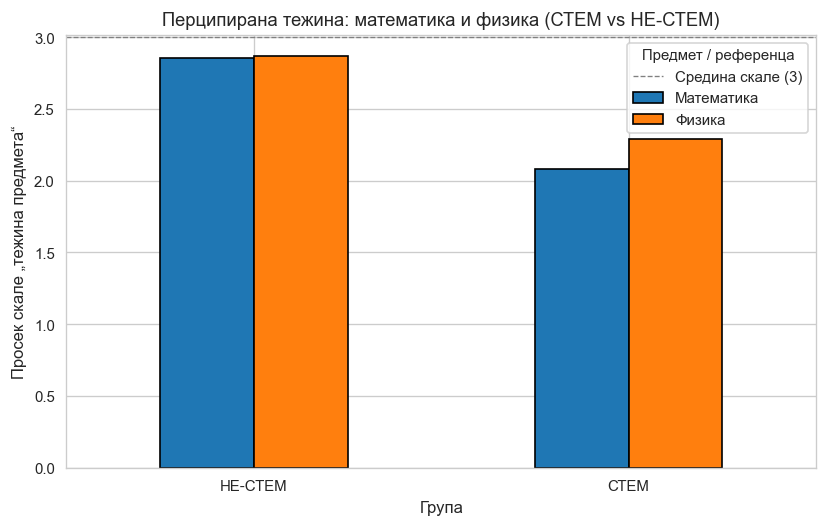

Welch t-тест, једнострано СТЕМ < НЕ-СТЕМ (scipy: alternative='less'):
Бонферонијева корекција за 2 теста: прилагођени праг значајности = 0.05/2 = 0.0250

  Математика: t=-9.471, p=0.000000 (n_stem=434, n_non=610, mean_stem=2.081, mean_non=2.856) -> значајно након Бонферонијеве корекције: да
  Физика: t=-7.428, p=0.000000 (n_stem=434, n_non=610, mean_stem=2.293, mean_non=2.872) -> значајно након Бонферонијеве корекције: да


In [82]:
tez_cols = ['Тежак [Математика]', 'Тежак [Физика]']
tmp = X[['СТЕМ']].copy()
for c in tez_cols:
    tmp[c] = X[c].map(likert_to_number)

means_tez = tmp.groupby('СТЕМ')[tez_cols].mean().round(3)
means_tez.columns = ['Математика', 'Физика']
means_tez.index = [STEM_LABELS.get(i, i) for i in means_tez.index]

print('Просечна пријављена тежина (већи број = теже; нижи просек = лакше):')
print(means_tez)

ax = means_tez.plot(kind='bar', rot=0, figsize=(7, 4.5), edgecolor='black')
plt.ylabel('Просек скале „тежина предмета“')
plt.xlabel('Група')
plt.title('Перципирана тежина: математика и физика (СТЕМ vs НЕ-СТЕМ)')
plt.axhline(y=3, color='grey', linestyle='--', linewidth=0.8, label='Средина скале (3)')
plt.legend(title='Предмет / референца')
plt.tight_layout()
plt.show()

ALPHA = 0.05
m = len(tez_cols)
alpha_bonferroni = ALPHA / m

print("Welch t-тест, једнострано СТЕМ < НЕ-СТЕМ (scipy: alternative='less'):")
print(f"Бонферонијева корекција за {m} теста: прилагођени праг значајности = {ALPHA}/{m} = {alpha_bonferroni:.4f}\n")
for col in tez_cols:
    a = tmp.loc[tmp['СТЕМ'] == 1, col].dropna()
    b = tmp.loc[tmp['СТЕМ'] == 0, col].dropna()
    res = ttest_ind(a, b, equal_var=False, alternative='less')
    predmet = col.replace('Тежак [', '').replace(']', '')
    znacajno_bonferroni = 'да' if res.pvalue < alpha_bonferroni else 'не'
    print(
        f"  {predmet}: t={res.statistic:.3f}, p={res.pvalue:.6f} "
        f"(n_stem={len(a)}, n_non={len(b)}, mean_stem={a.mean():.3f}, mean_non={b.mean():.3f}) "
        f"-> значајно након Бонферонијеве корекције: {znacajno_bonferroni}"
    )

**Закључак:** СТЕМ ученици перципирају математику (просек 2.081 наспрам 2.856) и физику (2.293 наспрам 2.872) као знатно лакше него НЕ-СТЕМ ученици — обе разлике су високо статистички значајне и после Бонферонијеве корекције (p<0.000001 за оба предмета, праг 0.025). Ово потврђује да ученици који бирају СТЕМ смер имају позитивнији однос према тежини ових предмета, а не само боље оцене.

## 3.3. Да ли су им занимљивији СТЕМ предмети (математика и физика)?

За **математику** и **физику** у основној школи питамо колико је предмет био **занимљив** (Ликерт, типично 1–5: **већи број = већа пријављена занимљивост**). **Виши просек** у групи СТЕМ у односу на НЕ-СТЕМ значи да те предмете **просечно доживљавају као занимљивије**.

Хипотеза се тестира Welch t-тестом (двострано), уз **Бонферонијеву корекцију** за 2 теста (математика, физика) — прилагођени праг значајности α/2.

Просечна пријављена занимљивост (већи број = занимљивије; виши просек = занимљивије):
         Математика  Физика
НЕ-СТЕМ       2.918   2.400
СТЕМ          3.947   3.334


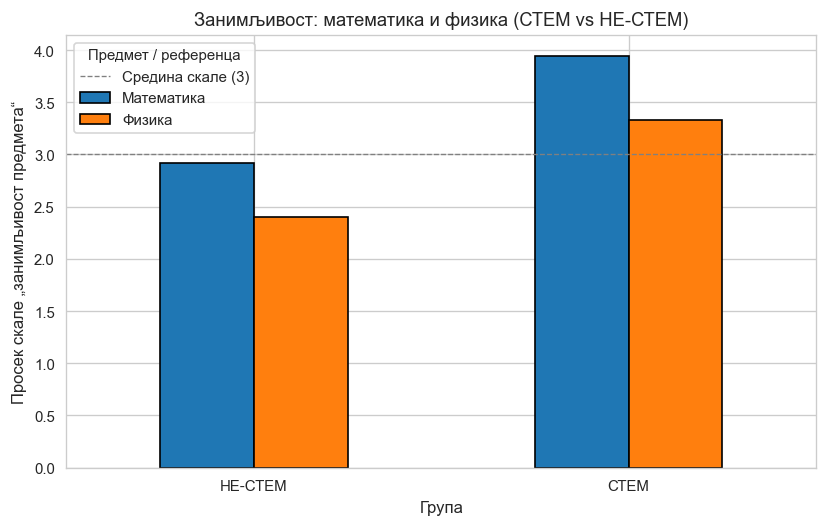

Welch t-тест, двострано (СТЕМ vs НЕ-СТЕМ):
Бонферонијева корекција за 2 теста: прилагођени праг значајности = 0.05/2 = 0.0250

  Математика: t=12.143, p=0.0000000000 (n_stem=434, n_non=610, mean_stem=3.947, mean_non=2.918) -> значајно након Бонферонијеве корекције: да
  Физика: t=10.689, p=0.0000000000 (n_stem=434, n_non=610, mean_stem=3.334, mean_non=2.400) -> значајно након Бонферонијеве корекције: да


In [83]:
zan_cols = ['Занимљив [Математика]', 'Занимљив [Физика]']
tmp_z = X[['СТЕМ']].copy()
for c in zan_cols:
    tmp_z[c] = X[c].map(likert_to_number)

means_zan = tmp_z.groupby('СТЕМ')[zan_cols].mean().round(3)
means_zan.columns = ['Математика', 'Физика']
means_zan.index = [STEM_LABELS.get(i, i) for i in means_zan.index]

print('Просечна пријављена занимљивост (већи број = занимљивије; виши просек = занимљивије):')
print(means_zan)

ax = means_zan.plot(kind='bar', rot=0, figsize=(7, 4.5), edgecolor='black')
plt.ylabel('Просек скале „занимљивост предмета“')
plt.xlabel('Група')
plt.title('Занимљивост: математика и физика (СТЕМ vs НЕ-СТЕМ)')
plt.axhline(y=3, color='grey', linestyle='--', linewidth=0.8, label='Средина скале (3)')
plt.legend(title='Предмет / референца')
plt.tight_layout()
plt.show()

ALPHA = 0.05
m = len(zan_cols)
alpha_bonferroni = ALPHA / m

print("Welch t-тест, двострано (СТЕМ vs НЕ-СТЕМ):")
print(f"Бонферонијева корекција за {m} теста: прилагођени праг значајности = {ALPHA}/{m} = {alpha_bonferroni:.4f}\n")
for col in zan_cols:
    a = tmp_z.loc[tmp_z['СТЕМ'] == 1, col].dropna()
    b = tmp_z.loc[tmp_z['СТЕМ'] == 0, col].dropna()
    res = ttest_ind(a, b, equal_var=False)
    predmet = col.replace('Занимљив [', '').replace(']', '')
    znacajno_bonferroni = 'да' if res.pvalue < alpha_bonferroni else 'не'
    print(
        f"  {predmet}: t={res.statistic:.3f}, p={res.pvalue:.10f} "
        f"(n_stem={len(a)}, n_non={len(b)}, mean_stem={a.mean():.3f}, mean_non={b.mean():.3f}) "
        f"-> значајно након Бонферонијеве корекције: {znacajno_bonferroni}"
    )

**Закључак:** СТЕМ ученици оцењују математику (просек 3.947 наспрам 2.918) и физику (3.334 наспрам 2.400) као знатно занимљивије него НЕ-СТЕМ ученици — разлика прелази један поен на скали 1–5 за оба предмета и статистички је високо значајна и после Бонферонијеве корекције (p<0.0001, праг 0.025). Занимљивост предмета показује се као један од најизраженијих показатеља СТЕМ опредељења међу свим до сада разматраним варијаблама.

## 3.4. Да ли су им кориснији СТЕМ предмети (математика и физика)?

За **математику** и **физику** у основној школи питамо колико је предмет био **користан** (Ликерт, типично 1–5: **већи број = већа пријављена корисност**). **Виши просек** у групи СТЕМ у односу на НЕ-СТЕМ значи да **у просеку приписују већу корисност** тим предметима на скали.

Хипотеза се тестира Welch t-тестом, једнострано (СТЕМ > НЕ-СТЕМ), уз **Бонферонијеву корекцију** за 2 теста (математика, физика) — прилагођени праг значајности α/2.

Просечна пријављена корисност (већи број = корисније; виши просек = корисније):
         Математика  Физика
НЕ-СТЕМ       3.574   2.702
СТЕМ          4.200   3.380


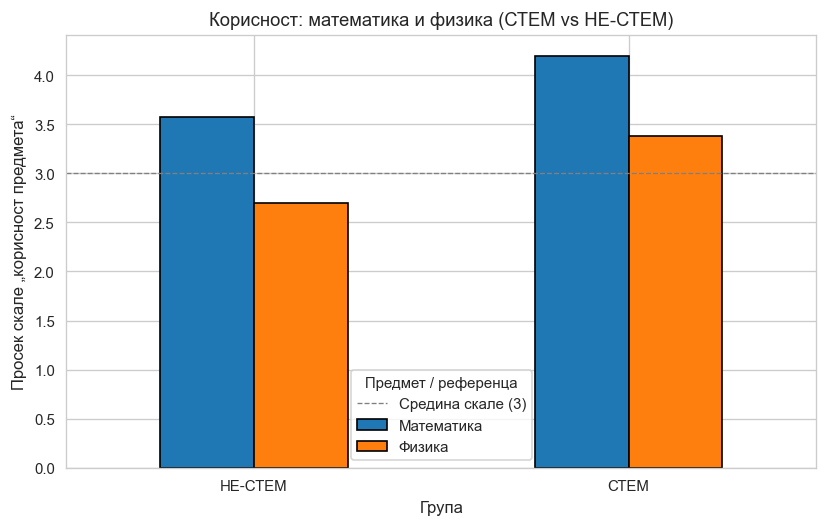

Welch t-тест, једнострано СТЕМ > НЕ-СТЕМ (scipy: alternative='greater'):
Бонферонијева корекција за 2 теста: прилагођени праг значајности = 0.05/2 = 0.0250

  Математика: t=7.999, p=0.0000000000 (n_stem=434, n_non=610, mean_stem=4.200, mean_non=3.574) -> значајно након Бонферонијеве корекције: да
  Физика: t=7.864, p=0.0000000000 (n_stem=434, n_non=610, mean_stem=3.380, mean_non=2.702) -> значајно након Бонферонијеве корекције: да


In [84]:
kor_cols = ['Користан [Математика]', 'Користан [Физика]']
tmp_k = X[['СТЕМ']].copy()
for c in kor_cols:
    tmp_k[c] = X[c].map(likert_to_number)

means_kor = tmp_k.groupby('СТЕМ')[kor_cols].mean().round(3)
means_kor.columns = ['Математика', 'Физика']
means_kor.index = [STEM_LABELS.get(i, i) for i in means_kor.index]

print('Просечна пријављена корисност (већи број = корисније; виши просек = корисније):')
print(means_kor)

ax = means_kor.plot(kind='bar', rot=0, figsize=(7, 4.5), edgecolor='black')
plt.ylabel('Просек скале „корисност предмета“')
plt.xlabel('Група')
plt.title('Корисност: математика и физика (СТЕМ vs НЕ-СТЕМ)')
plt.axhline(y=3, color='grey', linestyle='--', linewidth=0.8, label='Средина скале (3)')
plt.legend(title='Предмет / референца')
plt.tight_layout()
plt.show()

ALPHA = 0.05
m = len(kor_cols)
alpha_bonferroni = ALPHA / m

print("Welch t-тест, једнострано СТЕМ > НЕ-СТЕМ (scipy: alternative='greater'):")
print(f"Бонферонијева корекција за {m} теста: прилагођени праг значајности = {ALPHA}/{m} = {alpha_bonferroni:.4f}\n")
for col in kor_cols:
    a = tmp_k.loc[tmp_k['СТЕМ'] == 1, col].dropna()
    b = tmp_k.loc[tmp_k['СТЕМ'] == 0, col].dropna()
    res = ttest_ind(a, b, equal_var=False, alternative='greater')
    predmet = col.replace('Користан [', '').replace(']', '')
    znacajno_bonferroni = 'да' if res.pvalue < alpha_bonferroni else 'не'
    print(
        f"  {predmet}: t={res.statistic:.3f}, p={res.pvalue:.10f} "
        f"(n_stem={len(a)}, n_non={len(b)}, mean_stem={a.mean():.3f}, mean_non={b.mean():.3f}) "
        f"-> значајно након Бонферонијеве корекције: {znacajno_bonferroni}"
    )

**Закључак:** СТЕМ ученици перципирају математику (просек 4.200 наспрам 3.574) и физику (3.380 наспрам 2.702) као корисније за своју будућност него НЕ-СТЕМ ученици — разлика је статистички високо значајна и после Бонферонијеве корекције (p<0.0001, праг 0.025) за оба предмета. Заједно са резултатима из 3.1–3.3, ово показује конзистентан образац: СТЕМ ученици имају боље оцене и доживљавају ове предмете као лакше, занимљивије и корисније.

## 3.5. $\chi^2$ тест независности (пол × СТЕМ)

Градимо контингенцијску табелу и примењујемо `chi2_contingency` из SciPy.

In [85]:
ct = pd.crosstab(X['Пол:'], X['СТЕМ'], margins=True)
print(ct)

ct_core = pd.crosstab(X['Пол:'], X['СТЕМ'])
chi2, p, dof, expected = chi2_contingency(ct_core)
print(f'χ² = {chi2:.4f}, p-value = {p:.6f}, степени слободе = {dof}')

print('\nОчекиване фреквенције (претпоставка χ² теста: све ≥ 5):')
expected_df = pd.DataFrame(expected, index=ct_core.index, columns=ct_core.columns).round(2)
print(expected_df)
print(f"\nНајмања очекивана фреквенција: {expected.min():.2f} "
      f"-> претпоставка {'испуњена' if expected.min() >= 5 else 'НИЈЕ испуњена'}")

СТЕМ      0    1   All
Пол:                  
женски  476  239   715
мушки   134  195   329
All     610  434  1044
χ² = 60.8990, p-value = 0.000000, степени слободе = 1

Очекиване фреквенције (претпоставка χ² теста: све ≥ 5):
СТЕМ         0       1
Пол:                  
женски  417.77  297.23
мушки   192.23  136.77

Најмања очекивана фреквенција: 136.77 -> претпоставка испуњена


**Закључак:** постоји статистички значајна повезаност између пола и СТЕМ опредељења (χ²=60.899, p<0.000001, степени слободе = 1; претпоставка о минималној очекиваној фреквенцији испуњена, минимум 136.77). Мушки ученици бирају СТЕМ смер пропорционално чешће (195 од 329, ≈59.3%) него женски ученици (239 од 715, ≈33.4%), у складу са небалансираном родном структуром узорка примећеном у одељку 2.2.

## 3.6. $\chi^2$ тест независности (Одрастао/ла сам у: × СТЕМ)

Иста логика, за место одрастања (град/варошица/село) наспрам СТЕМ опредељења.

In [86]:
ct_odrastao = pd.crosstab(X['Одрастао/ла сам у:'], X['СТЕМ'], margins=True)
print(ct_odrastao)

ct_odrastao_core = pd.crosstab(X['Одрастао/ла сам у:'], X['СТЕМ'])
chi2, p, dof, expected = chi2_contingency(ct_odrastao_core)
print(f'χ² = {chi2:.4f}, p-value = {p:.6f}, степени слободе = {dof}')

print('\nОчекиване фреквенције (претпоставка χ² теста: све ≥ 5):')
expected_df = pd.DataFrame(expected, index=ct_odrastao_core.index, columns=ct_odrastao_core.columns).round(2)
print(expected_df)
print(f"\nНајмања очекивана фреквенција: {expected.min():.2f} "
      f"-> претпоставка {'испуњена' if expected.min() >= 5 else 'НИЈЕ испуњена'}")

СТЕМ                  0    1   All
Одрастао/ла сам у:                
варошици             62   33    95
већем граду         399  313   712
мањем граду          47   51    98
селу                102   37   139
All                 610  434  1044
χ² = 20.7175, p-value = 0.000120, степени слободе = 3

Очекиване фреквенције (претпоставка χ² теста: све ≥ 5):
СТЕМ                     0       1
Одрастао/ла сам у:                
варошици             55.51   39.49
већем граду         416.02  295.98
мањем граду          57.26   40.74
селу                 81.22   57.78

Најмања очекивана фреквенција: 39.49 -> претпоставка испуњена


**Закључак:** постоји статистички значајна повезаност између места одрастања и СТЕМ опредељења (χ²=20.7175, p=0.00012, степени слободе = 3; претпоставка о минималној очекиваној фреквенцији испуњена, минимум 39.49). Удео СТЕМ ученика варира од ≈26.6% (село) и ≈34.7% (варошица) до ≈44.0% (већи град) и чак ≈52.0% (мањи град) — ученици из села пропорционално најређе бирају СТЕМ смер, док они из мањих градова то чине најчешће.

# 4. Предобрада података за моделовање

Пре него што подаци буду коришћени за тренирање предиктивних модела, потребно је спровести низ корака предобраде: уклањање непотребних/ризичних колона, обраду недостајућих вредности, детекцију дупликата и аномалија, енкодирање категоријских и скалирање нумеричких обележја, поделу на тренинг/тест скуп и селекцију обележја.

## 4.1. Уклањање непотребних колона

### Претходно већ искључене колоне

Пет колона је искључено раније, у одељку 1.4.1, приликом дефинисања матрице обележја `X`: `Timestamp` и четири слободнотекстуалне колоне (`Занимање твоје мајке:`, `Занимање твог оца:`, `Зашто сте изабрали да упишите Гимназију?`, `Зашто сте изабрали да упишете овај смер?`). Разлог је исти као и овде — описни/слободнотекстуални карактер који захтева NLP или додатно кодирање пре него што би могле да се користе као обележја модела.

### Циљна променљива и њен извор

Из `X` уклањамо и:

- **`СТЕМ`** — сама циљна променљива не сме бити присутна међу улазним обележјима модела.
- **`Смер:`** — изворна колона из које је `СТЕМ` директно изведена (правило: 1 ако вредност припада листи `stem_smerovi`, иначе 0); њено задржавање би представљало директно „цурење“ циљне вредности у модел (data leakage).

### Административне/институционалне колоне (нису прави фактор опредељења)

Поред горе наведеног, уклањамо и следеће три колоне:

- **`Похађам средњу школу:`** — идентитет једне од четири конкретне школе из узорка. Иако би ова колона потенцијално могла показати одређену повезаност са циљном променљивом (нпр. ако поједине школе структурно нуде специфична СТЕМ одељења, попут раног специјализованог математичког одељења), таква повезаност не би представљала реалну слику стварних фактора опредељења ученика, већ институционалну/понудну карактеристику конкретне школе — не лични фактор о коме овај рад говори. Такође, задржавање овакве колоне не би било генерализабилно ван ова четири конкретне школе из узорка.
- **`Разред:`** и **`Година рођења:`** — обе колоне носе слаб, али реалан сигнал искључиво преко исте уске подгрупе ученика у раним специјализованим одељењима (сви редови са `Разред: 7` или `8`, као и рођени 2010/2011. године, припадају СТЕМ групи — видети одељак 1.3.1). Хронолошки, тренутни разред и година рођења не могу бити *разлог* избора смера јер се одређују независно од (и после) саме одлуке о упису; њихова привидна предиктивна моћ потиче искључиво од исте институционалне особености, а не од стварног фактора опредељења.

**Напомена:** уклањање ових колона из `X` не значи да се подаци губе — `df` и даље садржи све оригиналне колоне и могу се користити за било какву описну анализу, подгрупне прегледе или анализу робусности касније у раду.

In [87]:
kolone_za_izbacivanje_4_1 = [
    'СТЕМ',
    'Смер:',
    'Похађам средњу школу:',
    'Разред:',
    'Година рођења:',
]

print('Број колона у X пре уклањања:', X.shape[1])

X = X.drop(columns=kolone_za_izbacivanje_4_1)

print('Број уклоњених колона:', len(kolone_za_izbacivanje_4_1))
print('Број колона у X после уклањања:', X.shape[1])
print('\nПреостале колоне у X:')
print(X.columns.tolist())

Број колона у X пре уклањања: 101
Број уклоњених колона: 5
Број колона у X после уклањања: 96

Преостале колоне у X:
['Пол:', 'Одрастао/ла сам у:', 'Основну школу сам завршио/ла у:', 'Стручна спрема твоје мајке:', 'Стручна спрема твог оца:', 'Колико има деце у твојој породици, рачунајући и тебе (упиши број):', 'Какав си био/ла ђак у основној школи?', 'Најомиљенији предмет:', 'Други омиљени предмет (омиљени предмет, мање омиљени од претходног):', 'Трећи омиљени предмет (омиљени предмет, мање омиљени од претходна два):', 'Тежак [Српски језик и књижевност]', 'Тежак [Енглески језик]', 'Тежак [2. страни језик]', 'Тежак [Историја]', 'Тежак [Географија]', 'Тежак [Биологија]', 'Тежак [Математика]', 'Тежак [Информатика]', 'Тежак [Физика]', 'Тежак [Хемија]', 'Тежак [Музичка култура]', 'Тежак [Ликовна култура]', 'Тежак [Физичко васпитање]', 'Тежак [Техника и технологија]', 'Користан [Српски језик и књижевност]', 'Користан [Енглески језик]', 'Користан [2. страни језик]', 'Користан [Историја]', 'Ко

## 4.2. Обрада недостајућих вредности

Проверавамо да ли је, након уклањања колона у одељку 4.1, потребна додатна обрада недостајућих вредности. У одељку 1.2.1 је већ утврђено да изворни скуп података нема ниједну недостајућу вредност; овде проверавамо да ли је нека од претходних трансформација (нпр. претварање Ликерт одговора у бројеве у одељку 2.5.1) можда унела нове недостајуће вредности у `X`.

In [88]:
missing_X = X.isna().sum()
missing_X_cols = missing_X[missing_X > 0]

if len(missing_X_cols) == 0:
    print("Нема недостајућих вредности ни у једној од", X.shape[1], "преосталих колона у X.")
else:
    print(f"Број колона са недостајућим вредностима: {len(missing_X_cols)}")
    print(missing_X_cols)

Нема недостајућих вредности ни у једној од 96 преосталих колона у X.


**Закључак:** `X` и даље нема ниједну недостајућу вредност — ни уклањање колона у 4.1, ни ранија конверзија Ликерт одговора у бројеве нису унели нове `NaN` вредности. Пошто нема недостајућих вредности, импутација (нпр. попуњавање медијаном/модом) овде није потребна. Овај корак ипак остаје документован као стандардни део тока предобраде, и био би неопходан да се модел касније примени на нове, стварне податке који могу садржати недостајуће одговоре.

## 4.3. Детекција дупликата

Проверавамо да ли скуп података садржи потпуно идентичне (дуплиране) редове, занемарујући колону `Timestamp` — различито време уноса не значи да су одговори заиста различити, јер је исти ученик могао случајно послати анкету два пута.

In [89]:
df_bez_timestamp = df.drop(columns=['Timestamp'])
duplikati_mask = df_bez_timestamp.duplicated(keep=False)

print(f"Број редова укључених у неки дупликат (занемарујући Timestamp): {duplikati_mask.sum()}")
print(df.loc[duplikati_mask, ['Timestamp', 'Пол:', 'Година рођења:', 'Похађам средњу школу:', 'Смер:', 'Разред:']])

Број редова укључених у неки дупликат (занемарујући Timestamp): 2
                  Timestamp   Пол:  Година рођења:  \
634 2023-12-15 09:15:43.378  мушки            2009   
636 2023-12-15 11:17:37.350  мушки            2009   

            Похађам средњу школу:       Смер:  Разред:  
634  Другу крагујевачку гимназију  општи смер      1.0  
636  Другу крагујевачку гимназију  општи смер      1.0  


**Закључак:** пронађена су два реда (индекси 634 и 636) која су идентична у свим одговорима осим у `Timestamp`-у — оба потичу од ученика мушког пола, рођеног 2009. године, из Друге крагујевачке гимназије, општег смера, 1. разреда, поднета истог дана са размаком од само два сата. Идентичност преко готово 100 питања практично искључује случајну подударност — ово веома вероватно представља исто лице које је нехотично попунило анкету два пута. Задржавамо први унос (индекс 634), а каснији дупликат (индекс 636) уклањамо — из `df`, `X` и `y`, како би сви остали међусобно усклађени.

In [90]:
duplikati_za_brisanje = df_bez_timestamp[df_bez_timestamp.duplicated(keep='first')].index

print(f"Индекси редова који се бришу (каснији дупликат): {duplikati_za_brisanje.tolist()}")

df = df.drop(index=duplikati_za_brisanje)
X = X.drop(index=duplikati_za_brisanje)
y = y.drop(index=duplikati_za_brisanje)

print(f"\nБрој редова: df={df.shape[0]}, X={X.shape[0]}, y={y.shape[0]}")

Индекси редова који се бришу (каснији дупликат): [636]

Број редова: df=1043, X=1043, y=1043


## 4.4. Детекција аномалија

Детектујемо изразите аутлајере/аномалије у подацима помоћу Isolation Forest алгоритма, примењеног на нумеричке колоне у `X` (категоријске колоне се енкодирају тек у наредном одељку 4.5, па се овде не укључују). Са подразумеваном `contamination='auto'` вредношћу алгоритам означава непрактично велик удео узорка као аномалију (преко трећине свих редова), што показује да овако висока димензионалност (86 нумеричких колона) захтева фиксирану, мању вредност `contamination` параметра.

Поред Isolation Forest резултата, проверавамо и једноставнији, лакше тумачив показатељ: **број различитих вредности које је сваки ученик користио** кроз свих ~86 нумеричких (оцена и Ликерт) питања. Ученик који искрено и пажљиво одговара на толико разнородних питања (о 14 различитих предмета и темама попут навика учења, подршке родитеља, итд.) готово сигурно ће искористити већи део опсега скале (1–5). Одговор који кроз готово 90 различитих питања користи само 2–3 вредности представља класичан образац „straight-lining“ — небрижљивог/аутоматског попуњавања анкете без читања питања — а не стваран, нијансиран став ученика.

In [91]:
from sklearn.ensemble import IsolationForest

numericke_kolone = X.select_dtypes(include=[np.number]).columns.tolist()
print(f"Број нумеричких колона укључених у детекцију: {len(numericke_kolone)} од укупно {X.shape[1]}")

iso_forest = IsolationForest(contamination=0.02, random_state=42)
if_oznake = pd.Series(
    iso_forest.fit_predict(X[numericke_kolone]),
    index=X.index,
)

print(f"Isolation Forest означио као аномалију: {(if_oznake == -1).sum()} редова ({(if_oznake == -1).mean() * 100:.1f}%)")

Број нумеричких колона укључених у детекцију: 86 од укупно 96
Isolation Forest означио као аномалију: 21 редова (2.0%)


In [92]:
broj_jedinstvenih = X[numericke_kolone].nunique(axis=1)

print("Расподела броја различитих вредности по реду:")
print(broj_jedinstvenih.value_counts().sort_index())

PRAG_JEDINSTVENIH = 3
straight_lining = broj_jedinstvenih[broj_jedinstvenih <= PRAG_JEDINSTVENIH]

preklapanje = sum(idx in if_oznake[if_oznake == -1].index for idx in straight_lining.index)
print(f"\nБрој редова са ≤{PRAG_JEDINSTVENIH} различите вредности кроз {len(numericke_kolone)} питања: {len(straight_lining)}")
print(f"Од тога, колико их је Isolation Forest такође означио: {preklapanje}/{len(straight_lining)}")

print("\nВредности које су ти ученици користили:")
for idx in straight_lining.index:
    print(f"  Индекс {idx}: {sorted(X.loc[idx, numericke_kolone].unique())}")

Расподела броја различитих вредности по реду:
2       5
3       3
4      19
5    1016
Name: count, dtype: int64

Број редова са ≤3 различите вредности кроз 86 питања: 8
Од тога, колико их је Isolation Forest такође означио: 4/8

Вредности које су ти ученици користили:
  Индекс 23: [np.int64(1), np.int64(3), np.int64(5)]
  Индекс 226: [np.int64(3), np.int64(5)]
  Индекс 227: [np.int64(1), np.int64(2), np.int64(5)]
  Индекс 368: [np.int64(1), np.int64(5)]
  Индекс 454: [np.int64(1), np.int64(5)]
  Индекс 460: [np.int64(1), np.int64(2), np.int64(5)]
  Индекс 561: [np.int64(1), np.int64(5)]
  Индекс 562: [np.int64(1), np.int64(5)]


**Закључак:** од укупно 1043 реда, чак 1016 (≈97%) користи свих пет вредности скале, што потврђује да је варијација одговора уобичајена и очекивана. Само 8 редова показује изразит образац „straight-lining“ — коришћење свега 2–3 (готово увек само крајњих, 1 и 5) вредности кроз скоро 90 различитих питања о 14 предмета и разноврсним темама, што није реалистичан образац искреног одговарања.

Ови редови се преклапају само делимично са скупом који је означио Isolation Forest (4/8) — Isolation Forest мери вишедимензионалну удаљеност од центра узорка, па пропушта случајеве попут константног наизменичног одговора „1“/„5“ на свако питање (који, у зависности од распореда, не мора деловати изразито удаљено у сваком појединачном правцу, али је сам по себи неуверљив образац). Зато ове редове уклањамо на основу директног, тумачивог критеријума (број различитих вредности), а не искључиво на основу Isolation Forest резултата.

Редове које је Isolation Forest означио, али који не показују овај образац, **задржавамо** — то су вероватно само ученици са стварно необичним, али уверљивим комбинацијама одговора, чије уклањање би без јасног оправдања нарушило разноврсност узорка важну за анализу правих фактора опредељења.

In [93]:
df = df.drop(index=straight_lining.index)
X = X.drop(index=straight_lining.index)
y = y.drop(index=straight_lining.index)

print(f"Број редова после уклањања аномалија: df={df.shape[0]}, X={X.shape[0]}, y={y.shape[0]}")

Број редова после уклањања аномалија: df=1035, X=1035, y=1035


## 4.5. Енкодирање категоријских променљивих

Категоријске (текстуалне) променљиве трансформишемо у нумерички облик погодан за моделе машинског учења. Преостале категоријске колоне у `X` делимо у две групе:

- **Номиналне** (немају природан редослед): `Пол:`, `Најомиљенији предмет:`, `Други омиљени предмет...`, `Трећи омиљени предмет...`. Ове колоне енкодирамо **one-hot** методом (`pd.get_dummies`).
- **Ординалне** (имају природан редослед): `Одрастао/ла сам у:` и `Основну школу сам завршио/ла у:` (село < варошица < мањи град < већи град, по степену урбанизације), `Стручна спрема твоје мајке:`/`твог оца:` (основна < средња < виша школа < факултет) и `Какав си био/ла ђак у основној школи?` (добар/а < врло добар/а < одличан/а — мапирано на исту 3–5 скалу која се користи за оцене у остатку података). Ове колоне мапирамо ручно на растуће целе бројеве, чиме се чува редослед који би one-hot енкодирање изгубило.

### `Колико има деце у твојој породици...`

Ова колона садржи слободан унос броја. У одељку 1.2.1 већ је уочено да један ред има вредност `/` уместо броја (валидан текст, али не и број — зато га `isna()` не хвата). Претварамо колону у нумерички тип (`pd.to_numeric`), чиме тај унос постаје `NaN`, и попуњавамо га медијаном колоне.

In [94]:
deca_kolona = 'Колико има деце у твојој породици, рачунајући и тебе (упиши број):'

X[deca_kolona] = pd.to_numeric(X[deca_kolona], errors='coerce')
broj_nevalidnih = X[deca_kolona].isna().sum()
print(f"Број редова где вредност није могла да се протумачи као број: {broj_nevalidnih}")

medijana_dece = X[deca_kolona].median()
X[deca_kolona] = X[deca_kolona].fillna(medijana_dece)
print(f"Попуњено медијаном: {medijana_dece}")

Број редова где вредност није могла да се протумачи као број: 1
Попуњено медијаном: 2.0


In [95]:
urbanizacija_mapa = {
    'селу': 1,
    'варошици': 2,
    'мањем граду': 3,
    'већем граду': 4,
}

X['Одрастао/ла сам у:'] = X['Одрастао/ла сам у:'].map(urbanizacija_mapa)
X['Основну школу сам завршио/ла у:'] = X['Основну школу сам завршио/ла у:'].map(urbanizacija_mapa)

obrazovanje_mapa = {
    'завршена основна школа': 1,
    'завршена средња школа': 2,
    'завршена виша школа': 3,
    'завршен факултет': 4,
}

X['Стручна спрема твоје мајке:'] = X['Стручна спрема твоје мајке:'].map(obrazovanje_mapa)
X['Стручна спрема твог оца:'] = X['Стручна спрема твог оца:'].map(obrazovanje_mapa)

djak_mapa = {
    'добар/а': 3,
    'врло добар/а': 4,
    'одличан/а': 5,
}

X['Какав си био/ла ђак у основној школи?'] = X['Какав си био/ла ђак у основној школи?'].map(djak_mapa)

ordinalne_kolone = [
    'Одрастао/ла сам у:',
    'Основну школу сам завршио/ла у:',
    'Стручна спрема твоје мајке:',
    'Стручна спрема твог оца:',
    'Какав си био/ла ђак у основној школи?',
]
print('Број недостајућих вредности после ординалног мапирања (треба да буде 0 за све):')
print(X[ordinalne_kolone].isna().sum())

Број недостајућих вредности после ординалног мапирања (треба да буде 0 за све):
Одрастао/ла сам у:                       0
Основну школу сам завршио/ла у:          0
Стручна спрема твоје мајке:              0
Стручна спрема твог оца:                 0
Какав си био/ла ђак у основној школи?    0
dtype: int64


In [96]:
nominalne_kolone = [
    'Пол:',
    'Најомиљенији предмет:',
    'Други омиљени предмет (омиљени предмет, мање омиљени од претходног):',
    'Трећи омиљени предмет (омиљени предмет, мање омиљени од претходна два):',
]

print('Број колона у X пре one-hot енкодирања:', X.shape[1])

X = pd.get_dummies(X, columns=nominalne_kolone, drop_first=True)

print('Број колона у X после one-hot енкодирања:', X.shape[1])

preostale_object_kolone = X.select_dtypes(include='object').columns.tolist()
print(f"\nПреостале object (некодиране) колоне у X: {preostale_object_kolone}")
print('Укупан број недостајућих вредности у X:', X.isna().sum().sum())

Број колона у X пре one-hot енкодирања: 96
Број колона у X после one-hot енкодирања: 132

Преостале object (некодиране) колоне у X: []
Укупан број недостајућих вредности у X: 0


**Закључак:** `X` је сада потпуно нумерички (нема више ниједне object колоне) и нема недостајућих вредности. One-hot енкодирање номиналних колона (пол и три омиљена предмета, сваки са 14 категорија) знатно је повећало укупан број колона; ординалне колоне су мапиране на растуће бројеве уместо да буду разложене на индикаторске колоне, чиме је сачуван њихов природни редослед.

## 4.6. Подела скупа података

Скуп података делимо на тренинг и тест подскуп (stratified train-test split), уз стратификацију по циљној променљивој `СТЕМ` како би удео СТЕМ/НЕ-СТЕМ ученика остао приближно исти у оба подскупа.

Ова подела је прва ограда против цурења информација: тест подскуп се од овог тренутка потпуно издваја и не учествује ни у једном кораку обучавања — ни у скалирању, ни у селекцији обележја, ни у подешавању хиперпараметара — све до коначне евалуације изабраног модела (поглавље 6).

Скалирање и селекцију обележја **не изводимо овде као једнократне кораке над целим тренинг скупом**. Оба корака се обучавају (`fit`) на подацима: скалирање рачуна средње вредности и девијације, а селекција бира обележја према њиховој повезаности са циљном променљивом. Ако се обуче над целим тренинг скупом пре унакрсне валидације, сваки валидациони фолд је већ „учествовао“ у тим одлукама, што даје благо оптимистичну процену перформанси. Зато их укључујемо у низ корака предобраде који се, заједно са моделом, изнова обучава у сваком фолду унакрсне валидације (поглавље 5). У наставку овог поглавља те кораке само припремамо и објашњавамо појединачно.

In [97]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Тренинг скуп: {X_train.shape[0]} редова")
print(f"Тест скуп: {X_test.shape[0]} редова")

print("\nУдео СТЕМ у тренинг скупу:")
print(y_train.value_counts(normalize=True).round(4))
print("\nУдео СТЕМ у тест скупу:")
print(y_test.value_counts(normalize=True).round(4))

Тренинг скуп: 828 редова
Тест скуп: 207 редова

Удео СТЕМ у тренинг скупу:
СТЕМ
0    0.587
1    0.413
Name: proportion, dtype: float64

Удео СТЕМ у тест скупу:
СТЕМ
0    0.5845
1    0.4155
Name: proportion, dtype: float64


**Закључак:** скуп је подељен у односу 80/20 (828 тренинг / 207 тест редова). Захваљујући стратификацији по `СТЕМ`, удео СТЕМ ученика остаје готово идентичан у оба подскупа (≈41.3% у тренинг скупу, ≈41.6% у тест скупу) — веома близу укупном уделу у целом скупу података. Од овог тренутка, `X_train`/`y_train` користимо за обучавање (`fit`) свих наредних трансформација (скалирање, селекција обележја) и модела, а `X_test`/`y_test` искључиво за коначну евалуацију.

## 4.7. Скалирање: која обележја и зашто унутар унакрсне валидације

Модели осетљиви на размеру обележја (логистичка регресија, SVM, KNN) захтевају да нумеричка обележја буду на упоредивом опсегу. `StandardScaler` од сваке вредности одузме средњу вредност обележја и подели је стандардном девијацијом — а те две статистике рачуна на подацима на којима се позове `fit`. Зато се `fit` мора извести искључиво на тренинг делу сваког фолда унакрсне валидације, а не једном на целом тренинг скупу: у супротном статистике скалирања „виде“ и валидационе редове тог фолда, што даје благо оптимистичну процену. Скалирање је стога део низа корака предобраде који се обучава изнова у сваком фолду (поглавље 5); овде само припремамо списак обележја која ће се скалирати.

**Скалирају се само права нумеричка обележја** — оцене, Ликертове скале (1–5) и ординално кодиране колоне (место одрастања, стручна спрема родитеља, каква си био ђак и сл.). **Бинарна/индикаторска обележја се не скалирају**: колоне настале one-hot кодирањем (`Пол:_мушки` и индикатори омиљених предмета) узимају само вредности 0 и 1. Стандардизацијом такве колоне њен коефицијент у моделу више не описује прелазак из једне категорије у другу (0 → 1), него „померање за једну стандардну девијацију“ вештачки скалиране индикаторске променљиве — што одд ratio интерпретацију (одељак 7.1) чини нејасном. Зато их прослеђујемо кроз низ корака непромењене, у складу са устаљеном праксом у примењеној регресији.

In [98]:
# Две групе обележја за низ корака предобраде (поглавље 5):
# скалирају се само права нумеричка; бинарне/индикаторске колоне се прослеђују непромењене.
binarne_kolone = X_train.select_dtypes(include='bool').columns.tolist()
numericke_za_skaliranje = [c for c in X_train.columns if c not in binarne_kolone]

# Провера: све бинарне колоне су резултат one-hot кодирања (одељак 4.5) и узимају вредности {0, 1}
one_hot_prefiksi = ('Пол:_', 'Најомиљенији предмет:_', 'Други омиљени предмет', 'Трећи омиљени предмет')
assert all(k.startswith(one_hot_prefiksi) for k in binarne_kolone)
assert all(set(X_train[k].unique()) <= {False, True} for k in binarne_kolone)

print(f'Бинарних/индикаторских колона (не скалирају се): {len(binarne_kolone)}')
print(f'  примери: {binarne_kolone[:5]}')
print(f'Правих нумеричких колона (скалирају се): {len(numericke_za_skaliranje)}')
print(f'  примери: {numericke_za_skaliranje[:5]}')
print(f'Укупно: {len(binarne_kolone) + len(numericke_za_skaliranje)} = {X_train.shape[1]}')

Бинарних/индикаторских колона (не скалирају се): 40
  примери: ['Пол:_мушки', 'Најомиљенији предмет:_Биологија', 'Најомиљенији предмет:_Географија', 'Најомиљенији предмет:_Енглески језик', 'Најомиљенији предмет:_Информатика']
Правих нумеричких колона (скалирају се): 92
  примери: ['Одрастао/ла сам у:', 'Основну школу сам завршио/ла у:', 'Стручна спрема твоје мајке:', 'Стручна спрема твог оца:', 'Колико има деце у твојој породици, рачунајући и тебе (упиши број):']
Укупно: 132 = 132


**Закључак:** обележја су подељена у две групе — 92 права нумеричка (скалирају се) и 40 бинарних/индикаторских насталих one-hot кодирањем (прослеђују се непромењена). Само скалирање се не изводи овде: оно је корак у низу предобраде који се, заједно са селекцијом обележја и моделом, обучава изнова у сваком фолду унакрсне валидације (поглавље 5). У наставку рада радимо са необрађеним `X_train` / `X_test`, а трансформације примењује низ корака.

## 4.8. Селекција обележја: ранг појединачне повезаности и избор броја обележја

За свако обележје рачунамо ANOVA F-тест (`f_classif`) наспрам циљне променљиве `СТЕМ` — колико се његова просечна вредност разликује између СТЕМ и НЕ-СТЕМ групе, аналогно t-тестовима из 3. поглавља. Тест рачунамо на `X_train` (скалирање не мења F-статистику, јер је трансформација по обележју афина).

Раније коришћен критеријум — „задржи сва обележја са p < 0.05“ — овде **не користимо као правило селекције**. Уз 132 обележја и праг α = 0.05, само случајношћу се очекује око 132 × 0.05 ≈ 6–7 лажно значајних обележја (проблем вишеструког тестирања), а фиксан праг уз то произвољно одлучује колико обележја модел добија. Уместо тога, **број обележја `k` третирамо као хиперпараметар** који се бира унакрсном валидацијом заједно са хиперпараметрима модела (поглавље 5) — тако избор броја обележја постаје део оптимизације модела, а не унапред задата одлука.

У наставку овог одељка ANOVA ранг користимо само као **увид** — која обележја појединачно најјаче раздвајају групе — ради поређења са налазима из 3. поглавља.

In [99]:
from sklearn.feature_selection import SelectKBest, f_classif

# ANOVA F-тест за свако обележје — само као увид у појединачну повезаност са СТЕМ.
# Стваран избор броја обележја (k) ради се у поглављу 5, унутар унакрсне валидације.
anova_rang = SelectKBest(score_func=f_classif, k='all').fit(X_train, y_train)

rezultati_selekcije = pd.DataFrame({
    'обележје': X_train.columns,
    'F_статистика': anova_rang.scores_,
    'p_вредност': anova_rang.pvalues_,
}).sort_values('p_вредност')

print('15 обележја са најнижом p-вредношћу (најзначајнија појединачна повезаност са СТЕМ):')
print(rezultati_selekcije.head(15).to_string(index=False))

15 обележја са најнижом p-вредношћу (најзначајнија појединачна повезаност са СТЕМ):
                                                                                                                                                          обележје  F_статистика   p_вредност
                                                                                                                                                 Занимљив [Физика]    125.502628 3.230307e-27
                                                                                                                                             Занимљив [Математика]    119.925059 3.734059e-26
                         Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Склоност ка одређеној групи предмета]     81.434988 1.249119e-18
                                                                                                                                                 Користан [Ф

In [100]:
ALPHA = 0.05
n_ukupno = X_train.shape[1]
n_znacajno = int((rezultati_selekcije['p_вредност'] < ALPHA).sum())
ocekivano_lazno = n_ukupno * ALPHA

print(f'Обележја са p < {ALPHA}: {n_znacajno} од {n_ukupno}')
print(f'Очекивани број лажно значајних само услед случајности ({n_ukupno} тестова × {ALPHA}): ≈{ocekivano_lazno:.1f}')
print('→ фиксан праг p < 0.05 није поуздано правило селекције; број обележја k бира се у поглављу 5.')

Обележја са p < 0.05: 65 од 132
Очекивани број лажно значајних само услед случајности (132 тестова × 0.05): ≈6.6
→ фиксан праг p < 0.05 није поуздано правило селекције; број обележја k бира се у поглављу 5.


**Закључак:** 65 од 132 обележја показује појединачну повезаност са СТЕМ на прагу p < 0.05 — али се при 132 теста само случајношћу очекује око 6–7 таквих, па овај праг не користимо као правило селекције. ANOVA ранг ипак даје користан увид: обележја на врху — занимљивост и корисност математике/физике, перципирана тежина тих предмета, најчешће оцене из математике/физике/хемије, склоност ка одређеној групи предмета, омиљени предмет (математика) и пол — у потпуности се поклапају са резултатима статистичких тестова из 3. поглавља, што потврђује конзистентност налаза кроз различите методе. Број обележја `k` који модел заиста користи бира се унакрсном валидацијом у поглављу 5, засебно за сваки модел.

# 5. Методологија развоја и евалуације модела

Пре тренирања и поређења више модела машинског учења (наредно поглавље), дефинишемо заједничку методологију која ће се доследно применити на сваки од њих: низ корака предобраде (скалирање и селекција обележја заједно са моделом), стратегију валидације, метрике евалуације, приступ фином подешавању хиперпараметара и Nested Cross-Validation за непристрасну процену перформанси.

## 5.1. Низ корака предобраде (Pipeline)

Скалирање нумеричких обележја (одељак 4.7) и селекција обележја (одељак 4.8) су кораци који се обучавају (`fit`) на подацима. Ако се изведу једном, над целим тренинг скупом, пре унакрсне валидације, онда сваки валидациони фолд у тој валидацији учествује у избору параметара скалирања и у избору обележја — процена перформанси тако постаје благо оптимистична (цурење информација из валидационог дела фолда).

Решење је да скалирање, селекцију обележја и модел вежемо у један **низ корака предобраде** (`Pipeline`), који се као целина `fit`-ује изнова у сваком фолду — само на тренинг делу тог фолда. Функција `napravi_pipeline(model)` враћа низ од три корака:

1. **`ColumnTransformer`** — `StandardScaler` примењен само на права нумеричка обележја; бинарне/индикаторске колоне се прослеђују непромењене.
2. **`SelectKBest(f_classif)`** — задржава `k` обележја са највишом ANOVA F-статистиком; `k` је хиперпараметар (бира се у одељцима 5.4–5.5).
3. **модел** — класификатор који се тренира на изабраним обележјима.

Исти низ корака користе сви модели у 6. поглављу, што омогућава поштено поређење: свака разлика у резултатима потиче од модела, а не од различите предобраде.

In [101]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression


def napravi_pipeline(model, numericke=None, binarne=None):
    """Низ корака: скалирање само нумеричких обележја → SelectKBest(k) → модел.
    Цео низ се fit-ује изнова у сваком фолду унакрсне валидације.
    numericke/binarne подразумевано су све колоне из одељка 4.7; могу се сузити
    (нпр. у анализи робусности у одељку 8.3, кад се неке колоне уклоне)."""
    numericke = numericke_za_skaliranje if numericke is None else numericke
    binarne = binarne_kolone if binarne is None else binarne
    pretprocesor = ColumnTransformer([
        ('skaliranje', StandardScaler(), numericke),
        ('bez_promene', 'passthrough', binarne),
    ])
    return Pipeline([
        ('pretprocesor', pretprocesor),
        ('selekcija', SelectKBest(score_func=f_classif)),
        ('model', model),
    ])


# Провера: низ се fit-ује од краја до краја на необрађеном X_train, k се задаје као параметар
primer = napravi_pipeline(LogisticRegression(max_iter=1000, random_state=42))
primer.set_params(selekcija__k=30).fit(X_train, y_train)
print('Кораци низа:', [naziv for naziv, _ in primer.steps])
print('Изабрано обележја (k=30):', int(primer.named_steps['selekcija'].get_support().sum()))
print('Хиперпараметри се задају с префиксом корака: selekcija__k, model__<параметар>')

Кораци низа: ['pretprocesor', 'selekcija', 'model']
Изабрано обележја (k=30): 30
Хиперпараметри се задају с префиксом корака: selekcija__k, model__<параметар>


## 5.2. Стратегија валидације (Stratified K-Fold Cross-validation)

Дефинишемо Stratified K-Fold шему за унакрсну валидацију на тренинг скупу, која у сваком fold-у чува пропорцију СТЕМ/НЕ-СТЕМ класа приближно исту као у целом тренинг скупу.

Број фолдова (K=5) стандардан је избор у литератури — довољно велики тренинг делови по фолду уз стабилну процену перформанси, а мањи од уобичајене алтернативе (K=10) због рачунске цене: ову шему касније комбинујемо са фином претрагом хиперпараметара и Nested Cross-Validation-ом на пет различитих модела, где се број тренирања брзо умножава.

In [102]:
from sklearn.model_selection import StratifiedKFold

N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

print(f"Stratified K-Fold: {N_SPLITS} фолдова")
for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train), start=1):
    udeo = y_train.iloc[val_idx].mean()
    print(f"  Fold {fold}: {len(tr_idx)} тренинг / {len(val_idx)} валидациони, удео СТЕМ у валидационом делу = {udeo:.3f}")

Stratified K-Fold: 5 фолдова
  Fold 1: 662 тренинг / 166 валидациони, удео СТЕМ у валидационом делу = 0.410
  Fold 2: 662 тренинг / 166 валидациони, удео СТЕМ у валидационом делу = 0.416
  Fold 3: 662 тренинг / 166 валидациони, удео СТЕМ у валидационом делу = 0.416
  Fold 4: 663 тренинг / 165 валидациони, удео СТЕМ у валидационом делу = 0.412
  Fold 5: 663 тренинг / 165 валидациони, удео СТЕМ у валидационом делу = 0.412


**Закључак:** свих 5 фолдова има удео СТЕМ ученика између 41.0% и 41.6%, готово идентично укупном уделу у тренинг скупу (≈41.3%) — стратификација ради исправно. Овај `skf` објекат (5 фолдова, `shuffle=True`, `random_state=42`) користимо доследно за унакрсну валидацију приликом поређења модела и подешавања хиперпараметара у наставку рада.

## 5.3. Метрике евалуације

Дефинишемо једну, поново употребљиву функцију за евалуацију модела која рачуна accuracy, precision, recall, F1 (macro и weighted) и ROC-AUC, и приказује confusion matrix. Ову функцију ће свих пет модела у наредном поглављу користити доследно, ради упоредивости резултата.

In [103]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix,
)


def evaluate_model(y_true, y_pred, y_proba=None, naziv_modela='Модел'):
    """Рачуна стандардне метрике евалуације за бинарну класификацију и приказује confusion matrix."""
    rezultati = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 (weighted)': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1 (macro)': f1_score(y_true, y_pred, average='macro', zero_division=0),
    }
    if y_proba is not None:
        rezultati['ROC-AUC'] = roc_auc_score(y_true, y_proba)

    print(f"Метрике евалуације — {naziv_modela}:")
    for naziv, vrednost in rezultati.items():
        print(f"  {naziv}: {vrednost:.3f}")

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5.5, 4.2))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=['НЕ-СТЕМ', 'СТЕМ'], yticklabels=['НЕ-СТЕМ', 'СТЕМ'],
    )
    plt.xlabel('Предвиђено')
    plt.ylabel('Стварно')
    plt.title(f'Матрица конфузије — {naziv_modela}')
    plt.tight_layout()
    plt.show()

    return rezultati, cm

Метрике евалуације — Logistic Regression (демо):
  Accuracy: 0.710
  Precision: 0.648
  Recall: 0.663
  F1 (weighted): 0.711
  F1 (macro): 0.703
  ROC-AUC: 0.784


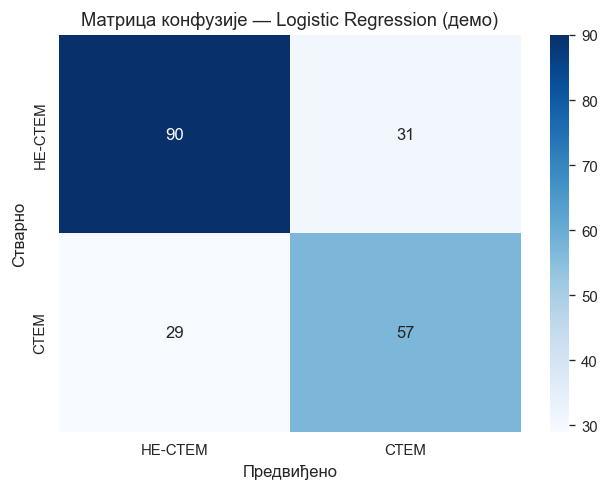

In [104]:
from sklearn.linear_model import LogisticRegression

# Демо низа корака: без селекције (k='all') и без подешавања хиперпараметара —
# само провера да предобрада + модел заједно дају смислен резултат.
demo_model = napravi_pipeline(LogisticRegression(max_iter=1000, random_state=42))
demo_model.set_params(selekcija__k='all')
demo_model.fit(X_train, y_train)

y_pred_demo = demo_model.predict(X_test)
y_proba_demo = demo_model.predict_proba(X_test)[:, 1]

demo_rezultati, demo_cm = evaluate_model(
    y_test, y_pred_demo, y_proba_demo, naziv_modela='Logistic Regression (демо)'
)

**Закључак:** функција `evaluate_model` исправно рачуна све тражене метрике и приказује матрицу конфузије. На демо низу корака (логистичка регресија без селекције обележја и без подешавања хиперпараметара, одељак 5.1) добијамо Accuracy ≈0.71 и ROC-AUC ≈0.78 — разумни резултати који потврђују да предобрада и модел заједно воде до класификатора који разликује СТЕМ и НЕ-СТЕМ ученике знатно боље од случајног погађања. Стварно поређење свих пет модела следи у наредном поглављу.

## 5.4. Фино подешавање хиперпараметара

Приказујемо две технике претраге хиперпараметара — исцрпну (`GridSearchCV`) и насумичну (`RandomizedSearchCV`) — демонстриране на једном репрезентативном моделу; примена на свих пет модела следи у наредном поглављу.

### 5.4.1. GridSearchCV

Исцрпна претрага унапред задате мреже вредности хиперпараметара.

In [105]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__l1_ratio': [1, 0],
    'selekcija__k': [10, 30, 50, 70, 90, 'all'],
}

grid_search = GridSearchCV(
    estimator=napravi_pipeline(
        LogisticRegression(max_iter=1000, solver='liblinear', random_state=42)
    ),
    param_grid=param_grid,
    scoring='f1_weighted',
    cv=skf,
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)

print('Најбољи параметри (GridSearchCV):', grid_search.best_params_)
print(f'Најбољи F1 (weighted) на унакрсној валидацији: {grid_search.best_score_:.3f}')

Најбољи параметри (GridSearchCV): {'model__C': 0.1, 'model__l1_ratio': 1, 'selekcija__k': 90}
Најбољи F1 (weighted) на унакрсној валидацији: 0.754


### 5.4.2. RandomizedSearchCV

Насумично узорковање комбинација хиперпараметара из задатих распона — ефикасније од `GridSearchCV` када је простор претраге велики.

In [106]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

param_dist = {
    'model__C': loguniform(1e-2, 1e2),
    'model__l1_ratio': [1, 0],
    'selekcija__k': [10, 30, 50, 70, 90, 'all'],
}

random_search = RandomizedSearchCV(
    estimator=napravi_pipeline(
        LogisticRegression(max_iter=1000, solver='liblinear', random_state=42)
    ),
    param_distributions=param_dist,
    n_iter=20,
    scoring='f1_weighted',
    cv=skf,
    random_state=42,
    n_jobs=-1,
)
random_search.fit(X_train, y_train)

print('Најбољи параметри (RandomizedSearchCV):', random_search.best_params_)
print(f'Најбољи F1 (weighted) на унакрсној валидацији: {random_search.best_score_:.3f}')

Најбољи параметри (RandomizedSearchCV): {'model__C': np.float64(0.14618962793704965), 'model__l1_ratio': 1, 'selekcija__k': 30}
Најбољи F1 (weighted) на унакрсној валидацији: 0.747


**Закључак:** обе технике на истом моделу (логистичка регресија) и истом простору претраге (`C`, `l1_ratio`, `k`) налазе врло сличан резултат — F1 (weighted) ≈0.75 на унакрсној валидацији, изнад неподешеног демоа (≈0.71 из одељка 5.3). `GridSearchCV` је исцрпно прегледао свих 60 комбинација (5 вредности `C` × 2 `l1_ratio` × 6 вредности `k`) и изабрао `k`=90; `RandomizedSearchCV` је насумично узорковао 20 комбинација (континуирани опсег за `C`, дискретне вредности за `l1_ratio` и `k`) и уз готово исти резултат изабрао `k`=30 — више вредности броја обележја даје сличне перформансе. Насумична претрага постаје значајно ефикаснија када простор претраге буде већи, као код осталих модела (SVM, Random Forest, XGBoost) у наредном поглављу.

## 5.5. Nested Cross-Validation

Комбинујемо унакрсну валидацију и фино подешавање хиперпараметара кроз угнежђену (nested) шему, како бисмо добили непристрасну процену перформанси модела која није „загађена“ истим подацима коришћеним за избор хиперпараметара.

У обичној (не-угнежђеној) шеми из одељка 5.4, исти CV фолдови користе се и за бирање најбољих хиперпараметара и за извештавање о резултату тог избора — што систематски даје донекле оптимистичну процену, јер је резултат „видео“ исте податке два пута. Nested CV ово решава помоћу два нивоа унакрсне валидације: **спољашњи** ниво (`skf` из 5.2) дели тренинг скуп на делове за непристрасну процену перформанси, док се **унутрашњи** ниво (нови `inner_cv`, такође Stratified K-Fold) користи искључиво унутар сваког спољашњег дела за бирање хиперпараметара — модел никада не „види“ спољашњи тест-део фолда приликом избора параметара.

In [107]:
from sklearn.model_selection import cross_val_score

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

nested_estimator = GridSearchCV(
    estimator=napravi_pipeline(
        LogisticRegression(max_iter=1000, solver='liblinear', random_state=42)
    ),
    param_grid=param_grid,
    cv=inner_cv,
    scoring='f1_weighted',
)

nested_scores = cross_val_score(
    nested_estimator, X_train, y_train, cv=skf, scoring='f1_weighted', n_jobs=-1
)

print('Nested CV резултати по спољашњем фолду:', nested_scores.round(3))
print(f'Nested CV просек F1 (weighted): {nested_scores.mean():.3f} ± {nested_scores.std():.3f}')
print(f'За поређење, не-угнежђени GridSearchCV.best_score_ из 5.4.1: {grid_search.best_score_:.3f}')

Nested CV резултати по спољашњем фолду: [0.761 0.746 0.747 0.74  0.73 ]
Nested CV просек F1 (weighted): 0.745 ± 0.010
За поређење, не-угнежђени GridSearchCV.best_score_ из 5.4.1: 0.754


**Закључак:** Nested CV просек (≈0.745 ± 0.010) је за око 0.01 нижи од не-угнежђене процене из 5.4.1 (≈0.754) — то је очекивани смер (не-угнежђена процена је благо оптимистична јер исте фолдове користи и за избор хиперпараметара и за извештавање), али је разлика унутар једне стандардне девијације, дакле занемарљива. Показује да процена перформансе логистичке регресије није вештачки побољшана подешавањем хиперпараметара. Иста шема (спољашњи `skf` + унутрашњи `inner_cv` унутар `GridSearchCV`-a) примениће се доследно на свих пет модела у наредном поглављу, где разлика између угнежђене и не-угнежђене процене може бити израженија код модела са већим и осетљивијим простором хиперпараметара (нпр. SVM, Random Forest, XGBoost).

# 6. Резултати и компаративна анализа модела

У овом поглављу тренирамо и упоређујемо свих пет модела машинског учења из теоријског оквира, користећи алатку изграђену у 5. поглављу (Stratified K-Fold, функција за евалуацију, GridSearchCV/RandomizedSearchCV).

## 6.1. Baseline модел (Dummy Classifier)

Тренирамо наиван референтни модел (`DummyClassifier`, стратегија `most_frequent` — увек предвиђа већинску класу) који служи као доња граница перформанси. Сваки стваран модел у наставку овог поглавља требало би да га јасно надмаши; у супротном, тај модел не би доносио никакву стварну предиктивну вредност у односу на тривијално нагађање.

Метрике евалуације — Baseline (Dummy Classifier):
  Accuracy: 0.585
  Precision: 0.000
  Recall: 0.000
  F1 (weighted): 0.431
  F1 (macro): 0.369
  ROC-AUC: 0.500


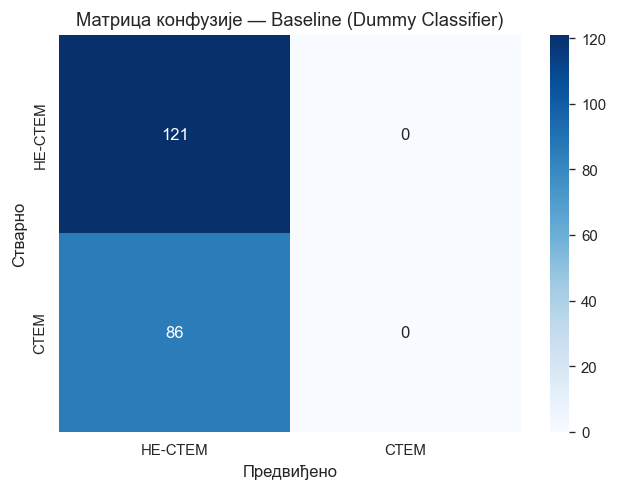

In [108]:
from sklearn.dummy import DummyClassifier

baseline_model = DummyClassifier(strategy='most_frequent', random_state=42)
baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)
y_proba_baseline = baseline_model.predict_proba(X_test)[:, 1]

baseline_rezultati, baseline_cm = evaluate_model(
    y_test, y_pred_baseline, y_proba_baseline, naziv_modela='Baseline (Dummy Classifier)'
)

**Закључак:** `DummyClassifier` увек предвиђа НЕ-СТЕМ (већинску класу), што даје Accuracy ≈0.585 (тачно једнако уделу НЕ-СТЕМ ученика у тест скупу), Precision и Recall = 0 за СТЕМ класу (никада је не предвиђа), и ROC-AUC = 0.5 (линија случајног погађања — модел нема способност разликовања класа). Ово су вредности које сваки од пет стварних модела у наставку мора јасно да надмаши да би се сматрао корисним.

## 6.2. Тренирање и евалуација модела

За сваки од пет модела спроводимо фино подешавање хиперпараметара и унакрсну валидацију, користећи исту методологију из 5. поглавља, ради поштеног поређења.

### 6.2.1. Логистичка регресија

Користимо већ подешен модел из одељка 5.4.1 (`grid_search.best_estimator_` — најбоља комбинација параметара `C`, `l1_ratio` и броја обележја `k`, пронађена унакрсном валидацијом на тренинг скупу) и извештавамо његове перформансе на тест скупу, који до сада ни на који начин није коришћен у обучавању или подешавању.

Најбољи параметри (из 5.4.1): {'model__C': 0.1, 'model__l1_ratio': 1, 'selekcija__k': 90}
CV F1 (weighted): 0.754 ± 0.019
Метрике евалуације — Logistic Regression:
  Accuracy: 0.729
  Precision: 0.674
  Recall: 0.674
  F1 (weighted): 0.729
  F1 (macro): 0.722
  ROC-AUC: 0.800


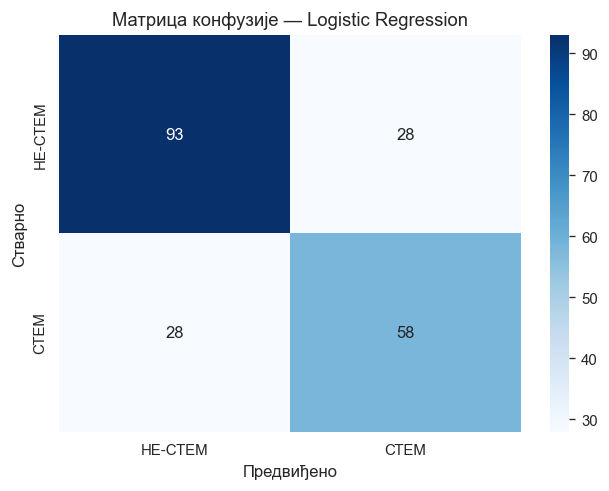

In [109]:
logreg_best = grid_search.best_estimator_
print('Најбољи параметри (из 5.4.1):', grid_search.best_params_)
_bi = grid_search.best_index_
logreg_cv = (grid_search.cv_results_['mean_test_score'][_bi], grid_search.cv_results_['std_test_score'][_bi])
print(f'CV F1 (weighted): {logreg_cv[0]:.3f} ± {logreg_cv[1]:.3f}')

y_pred_logreg = logreg_best.predict(X_test)
y_proba_logreg = logreg_best.predict_proba(X_test)[:, 1]

logreg_rezultati, logreg_cm = evaluate_model(
    y_test, y_pred_logreg, y_proba_logreg, naziv_modela='Logistic Regression'
)

**Закључак:** на унакрсној валидацији логистичка регресија постиже F1 (weighted) 0.754 ± 0.019 (изабрано `k`=90 обележја, `C`=0.1, L1 регуларизација). На тест скупу: Accuracy ≈0.73 и ROC-AUC ≈0.80 — знатно изнад baseline-а из 6.1 (Accuracy ≈0.585, ROC-AUC = 0.5). Вредности улазе у упоредну табелу (6.3) и на ROC график (6.4); поређење свих модела следи у 6.3–6.5.

### 6.2.2. K-Nearest Neighbors (KNN)

Претражујемо комбинације броја суседа, начина пондерисања суседа (`weights` — да ли сви суседи подједнако утичу на одлуку или ближи суседи имају већи утицај) и метрике удаљености, користећи исту `skf` шему унакрсне валидације.

Најбољи параметри (KNN): {'model__metric': 'euclidean', 'model__n_neighbors': 11, 'model__weights': 'uniform', 'selekcija__k': 50}
CV F1 (weighted): 0.745 ± 0.018
Метрике евалуације — KNN:
  Accuracy: 0.696
  Precision: 0.635
  Recall: 0.628
  F1 (weighted): 0.695
  F1 (macro): 0.686
  ROC-AUC: 0.766


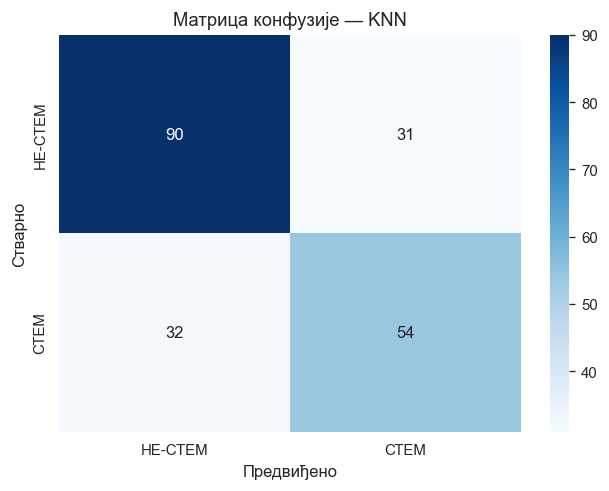

In [110]:
from sklearn.neighbors import KNeighborsClassifier

param_grid_knn = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 15],
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan'],
    'selekcija__k': [10, 30, 50, 70, 90, 'all'],
}

grid_knn = GridSearchCV(
    estimator=napravi_pipeline(KNeighborsClassifier()),
    param_grid=param_grid_knn,
    scoring='f1_weighted',
    cv=skf,
    n_jobs=-1,
)
grid_knn.fit(X_train, y_train)

print('Најбољи параметри (KNN):', grid_knn.best_params_)
_bi = grid_knn.best_index_
knn_cv = (grid_knn.cv_results_['mean_test_score'][_bi], grid_knn.cv_results_['std_test_score'][_bi])
print(f'CV F1 (weighted): {knn_cv[0]:.3f} ± {knn_cv[1]:.3f}')

knn_best = grid_knn.best_estimator_
y_pred_knn = knn_best.predict(X_test)
y_proba_knn = knn_best.predict_proba(X_test)[:, 1]

knn_rezultati, knn_cm = evaluate_model(y_test, y_pred_knn, y_proba_knn, naziv_modela='KNN')

**Закључак:** најбоља комбинација за KNN — еуклидска удаљеност, 11 суседа, `weights='uniform'`, `k`=50 обележја — даје CV F1 (weighted) 0.745 ± 0.018. На тест скупу: Accuracy ≈0.70 и ROC-AUC ≈0.77 — изнад baseline-а, али најслабије међу пет модела (детаљније у 6.5).

### 6.2.3. Support Vector Machine (SVM)

Претражујемо комбинације регуларизационог параметра `C` и типа кернела (линеаран или RBF), уз `probability=True` како бисмо могли да рачунамо ROC-AUC.

Најбољи параметри (SVM): {'model__C': 1, 'model__kernel': 'rbf', 'selekcija__k': 90}
CV F1 (weighted): 0.748 ± 0.014
Метрике евалуације — SVM:
  Accuracy: 0.787
  Precision: 0.769
  Recall: 0.698
  F1 (weighted): 0.786
  F1 (macro): 0.778
  ROC-AUC: 0.807


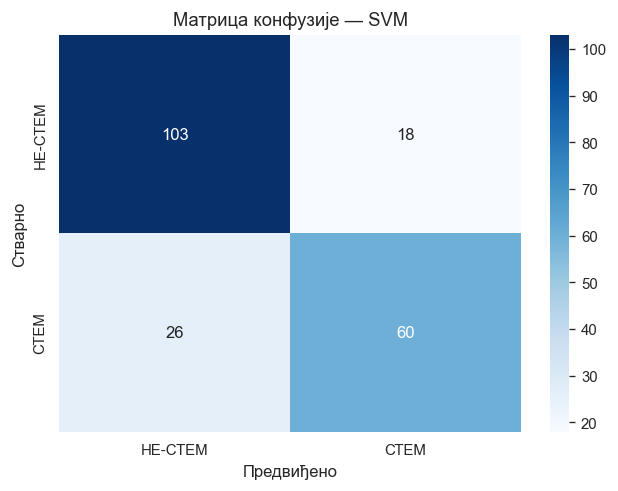

In [111]:
from sklearn.svm import SVC

param_grid_svm = {
    'model__C': [0.1, 1, 10],
    'model__kernel': ['linear', 'rbf'],
    'selekcija__k': [10, 30, 50, 70, 90, 'all'],
}

grid_svm = GridSearchCV(
    estimator=napravi_pipeline(SVC(probability=True, random_state=42)),
    param_grid=param_grid_svm,
    scoring='f1_weighted',
    cv=skf,
    n_jobs=-1,
)
grid_svm.fit(X_train, y_train)

print('Најбољи параметри (SVM):', grid_svm.best_params_)
_bi = grid_svm.best_index_
svm_cv = (grid_svm.cv_results_['mean_test_score'][_bi], grid_svm.cv_results_['std_test_score'][_bi])
print(f'CV F1 (weighted): {svm_cv[0]:.3f} ± {svm_cv[1]:.3f}')

svm_best = grid_svm.best_estimator_
y_pred_svm = svm_best.predict(X_test)
y_proba_svm = svm_best.predict_proba(X_test)[:, 1]

svm_rezultati, svm_cm = evaluate_model(y_test, y_pred_svm, y_proba_svm, naziv_modela='SVM')

**Закључак:** SVM са RBF кернелом, `C`=1 и `k`=90 обележја даје CV F1 (weighted) 0.748 ± 0.014. На тест скупу: Accuracy ≈0.79 и ROC-AUC ≈0.81. Појединачни резултат на тесту не служи за проглашавање „најбољег“ модела — то радимо тек у 6.3–6.5, на основу унакрсне валидације.

### 6.2.4. Random Forest

Претражујемо комбинације броја стабала (`n_estimators`), максималне дубине стабла (`max_depth`) и минималног броја узорака за поделу чвора (`min_samples_split`).

Најбољи параметри (Random Forest): {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 200, 'selekcija__k': 'all'}
CV F1 (weighted): 0.748 ± 0.019
Метрике евалуације — Random Forest:
  Accuracy: 0.754
  Precision: 0.754
  Recall: 0.605
  F1 (weighted): 0.748
  F1 (macro): 0.737
  ROC-AUC: 0.812


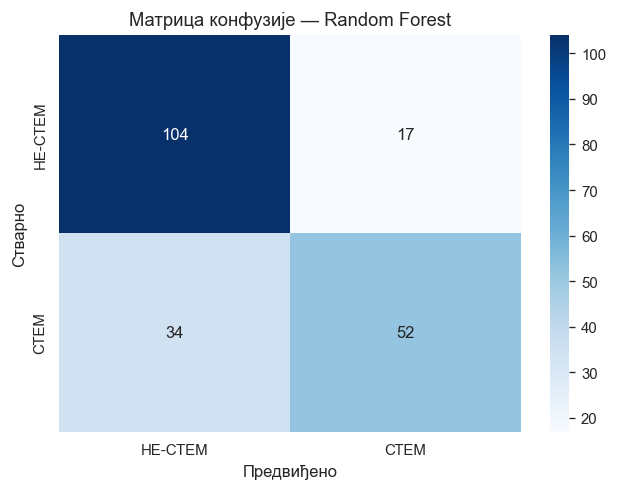

In [112]:
from sklearn.ensemble import RandomForestClassifier

param_grid_rf = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5],
    'selekcija__k': [10, 30, 50, 70, 90, 'all'],
}

grid_rf = GridSearchCV(
    estimator=napravi_pipeline(RandomForestClassifier(random_state=42)),
    param_grid=param_grid_rf,
    scoring='f1_weighted',
    cv=skf,
    n_jobs=-1,
)
grid_rf.fit(X_train, y_train)

print('Најбољи параметри (Random Forest):', grid_rf.best_params_)
_bi = grid_rf.best_index_
rf_cv = (grid_rf.cv_results_['mean_test_score'][_bi], grid_rf.cv_results_['std_test_score'][_bi])
print(f'CV F1 (weighted): {rf_cv[0]:.3f} ± {rf_cv[1]:.3f}')

rf_best = grid_rf.best_estimator_
y_pred_rf = rf_best.predict(X_test)
y_proba_rf = rf_best.predict_proba(X_test)[:, 1]

rf_rezultati, rf_cm = evaluate_model(y_test, y_pred_rf, y_proba_rf, naziv_modela='Random Forest')

**Закључак:** Random Forest (200 стабала, `max_depth=None`, `min_samples_split=5`) — једини модел коме је претрага определила `k`=`all`, тј. користи свих 132 обележја без селекције. CV F1 (weighted) 0.748 ± 0.019; на тест скупу Accuracy ≈0.75 и ROC-AUC ≈0.81.

### 6.2.5. XGBoost

Претражујемо комбинације броја стабала, максималне дубине и `learning_rate`-а. Санирање назива колона које је XGBoost раније захтевало (због карактера `[`, `]`) више није потребно — `ColumnTransformer` у низу корака враћа numpy низ без назива колона.

Најбољи параметри (XGBoost): {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100, 'selekcija__k': 90}
CV F1 (weighted): 0.752 ± 0.021
Метрике евалуације — XGBoost:
  Accuracy: 0.734
  Precision: 0.691
  Recall: 0.651
  F1 (weighted): 0.733
  F1 (macro): 0.724
  ROC-AUC: 0.810


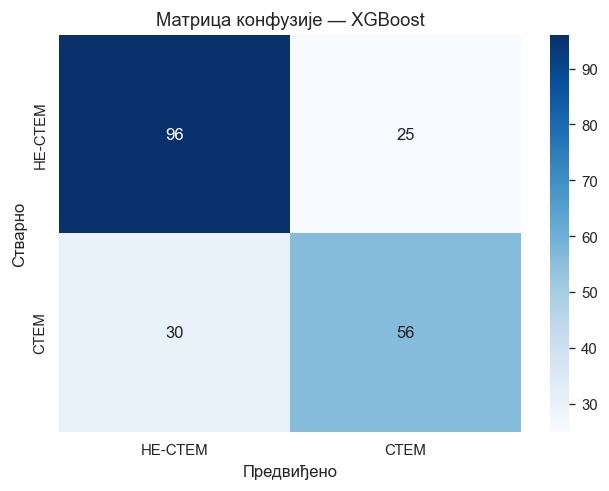

In [113]:
from xgboost import XGBClassifier

# ColumnTransformer у низу корака враћа numpy низ (без назива колона),
# па XGBoost нема проблем са карактерима `[`, `]` — санирање назива више није потребно.
param_grid_xgb = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [3, 5],
    'model__learning_rate': [0.05, 0.1, 0.2],
    'selekcija__k': [10, 30, 50, 70, 90, 'all'],
}

grid_xgb = GridSearchCV(
    estimator=napravi_pipeline(XGBClassifier(random_state=42, eval_metric='logloss')),
    param_grid=param_grid_xgb,
    scoring='f1_weighted',
    cv=skf,
    n_jobs=-1,
)
grid_xgb.fit(X_train, y_train)

print('Најбољи параметри (XGBoost):', grid_xgb.best_params_)
_bi = grid_xgb.best_index_
xgb_cv = (grid_xgb.cv_results_['mean_test_score'][_bi], grid_xgb.cv_results_['std_test_score'][_bi])
print(f'CV F1 (weighted): {xgb_cv[0]:.3f} ± {xgb_cv[1]:.3f}')

xgb_best = grid_xgb.best_estimator_
y_pred_xgb = xgb_best.predict(X_test)
y_proba_xgb = xgb_best.predict_proba(X_test)[:, 1]

xgb_rezultati, xgb_cm = evaluate_model(y_test, y_pred_xgb, y_proba_xgb, naziv_modela='XGBoost')

**Закључак:** XGBoost (`learning_rate`=0.1, `max_depth`=3, 100 стабала, `k`=90) даје CV F1 (weighted) 0.752 ± 0.021. На тест скупу: Accuracy ≈0.73 и ROC-AUC ≈0.81. Овим је завршено тренирање свих пет модела; поређење следи у 6.3–6.5.

## 6.3. Упоредна табела модела

Сакупљамо резултате свих шест модела (baseline + пет стварних модела) у једну табелу, сортирану по F1 (weighted), ради директног поређења.

                    CV F1 (w) ± SD  Accuracy  Precision  Recall  F1 (weighted)  F1 (macro)  ROC-AUC
SVM                  0.748 ± 0.014     0.787      0.769   0.698          0.786       0.778    0.807
Random Forest        0.748 ± 0.019     0.754      0.754   0.605          0.748       0.737    0.812
XGBoost              0.752 ± 0.021     0.734      0.691   0.651          0.733       0.724    0.810
Logistic Regression  0.754 ± 0.019     0.729      0.674   0.674          0.729       0.722    0.800
KNN                  0.745 ± 0.018     0.696      0.635   0.628          0.695       0.686    0.766
Baseline (Dummy)                 —     0.585      0.000   0.000          0.431       0.369    0.500


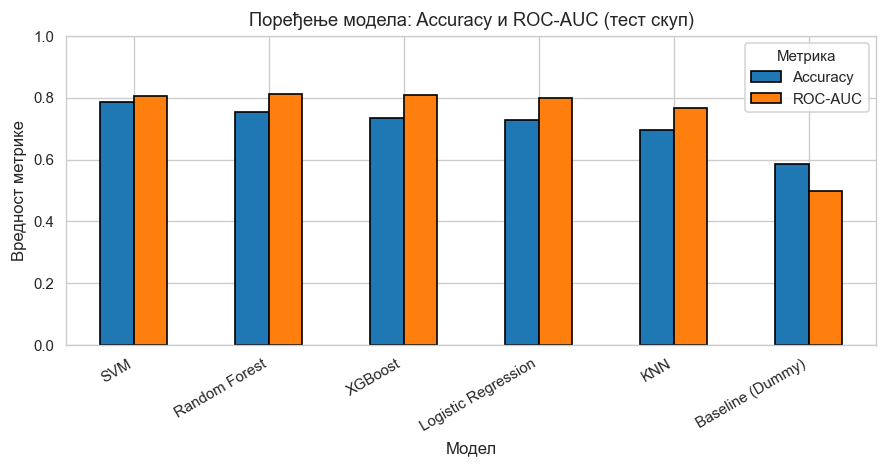

In [114]:
uporedna_tabela = pd.DataFrame({
    'Baseline (Dummy)': baseline_rezultati,
    'Logistic Regression': logreg_rezultati,
    'KNN': knn_rezultati,
    'SVM': svm_rezultati,
    'Random Forest': rf_rezultati,
    'XGBoost': xgb_rezultati,
}).T.round(3)

# CV F1 (weighted) — основа за поређење модела; тест скуп служи само за коначну процену
cv_f1 = {'Logistic Regression': logreg_cv, 'KNN': knn_cv, 'SVM': svm_cv,
         'Random Forest': rf_cv, 'XGBoost': xgb_cv}
uporedna_tabela.insert(0, 'CV F1 (w) ± SD', [
    f'{cv_f1[m][0]:.3f} ± {cv_f1[m][1]:.3f}' if m in cv_f1 else '—' for m in uporedna_tabela.index
])

uporedna_tabela = uporedna_tabela.sort_values('F1 (weighted)', ascending=False)
print(uporedna_tabela.to_string())

uporedna_tabela[['Accuracy', 'ROC-AUC']].plot(kind='bar', figsize=(7.5, 4), edgecolor='black')
plt.ylabel('Вредност метрике')
plt.xlabel('Модел')
plt.title('Поређење модела: Accuracy и ROC-AUC (тест скуп)')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1)
plt.legend(title='Метрика')
plt.tight_layout()
plt.show()

**Закључак:** табела спаја две ствари: **CV F1 (weighted)** — на основу које су модели подешавани и поређени — и метрике на **независном тест скупу** као коначну процену. CV F1 свих пет модела налази се у уском распону 0.745–0.754 (разлика 0.009), унутар међусобних стандардних девијација — по унакрсној валидацији модели су практично неразликиви. На тест скупу SVM има највишу Accuracy (0.787) и F1 (weighted) (0.786), а Random Forest највиши ROC-AUC (0.812; XGBoost 0.810, SVM 0.807 — готово изједначено). При n=207 оквирна 95% полуширина интервала за тачност износи ±0.06: разлика SVM–Random Forest (0.033) је унутар тог интервала, док једино KNN (0.696, разлика ≈0.09) поуздано заостаје. Изабрани број обележја варира по моделу (KNN `k`=50, SVM/LogReg/XGBoost `k`=90, Random Forest `k`=`all`) — не постоји један „тачан“ број. Детаљнија дискусија у 6.5.

## 6.4. ROC криве

Приказујемо ROC криве свих шест модела на једном графику ради визуелног поређења способности разликовања СТЕМ/НЕ-СТЕМ ученика, независно од избора прага одлуке.

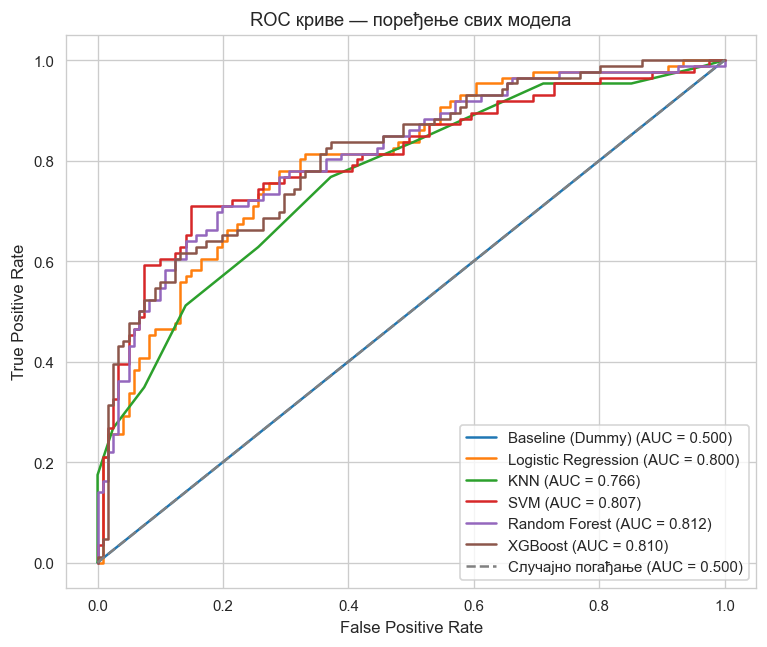

In [115]:
from sklearn.metrics import roc_curve

modeli_za_roc = {
    'Baseline (Dummy)': y_proba_baseline,
    'Logistic Regression': y_proba_logreg,
    'KNN': y_proba_knn,
    'SVM': y_proba_svm,
    'Random Forest': y_proba_rf,
    'XGBoost': y_proba_xgb,
}

plt.figure(figsize=(6.5, 5.5))
for naziv, y_proba in modeli_za_roc.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = uporedna_tabela.loc[naziv, 'ROC-AUC']
    plt.plot(fpr, tpr, label=f'{naziv} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Случајно погађање (AUC = 0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC криве — поређење свих модела')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Закључак:** криве свих пет стварних модела леже изнад дијагонале случајног погађања. Random Forest (AUC 0.812), XGBoost (0.810) и SVM (0.807) имају међусобно готово изједначене криве и највеће површине; Logistic Regression је нешто нижи (0.800), а KNN најближи дијагонали (0.766) — у складу са упоредном табелом (6.3).

## 6.5. Дискусија перформанси

Идентификујемо модел(е) са најбољим перформансама по различитим метрикама, као основу за дискусију резултата у тексту рада.

In [116]:
import numpy as np

najbolji_po_accuracy = uporedna_tabela['Accuracy'].idxmax()
najbolji_po_f1 = uporedna_tabela['F1 (weighted)'].idxmax()
najbolji_po_auc = uporedna_tabela['ROC-AUC'].idxmax()

print(f"Најбољи по Accuracy: {najbolji_po_accuracy} ({uporedna_tabela.loc[najbolji_po_accuracy, 'Accuracy']:.3f})")
print(f"Најбољи по F1 (weighted): {najbolji_po_f1} ({uporedna_tabela.loc[najbolji_po_f1, 'F1 (weighted)']:.3f})")
print(f"Најбољи по ROC-AUC: {najbolji_po_auc} ({uporedna_tabela.loc[najbolji_po_auc, 'ROC-AUC']:.3f})")

razlika_accuracy = uporedna_tabela.loc[najbolji_po_accuracy, 'Accuracy'] - uporedna_tabela.loc['Baseline (Dummy)', 'Accuracy']
print(f'\nРазлика у Accuracy између најбољег модела и baseline-а: {razlika_accuracy:.3f}')

# Да ли су разлике међу стварним моделима значајне?
stvarni = ['Logistic Regression', 'KNN', 'SVM', 'Random Forest', 'XGBoost']
acc_stvarni = uporedna_tabela.loc[stvarni, 'Accuracy']
p_sr = acc_stvarni.mean()
ci_pola = 1.96 * np.sqrt(p_sr * (1 - p_sr) / len(y_test))
cv_raspon = (min(cv_f1[m][0] for m in stvarni), max(cv_f1[m][0] for m in stvarni))
print(f'\nCV F1 (weighted) пет модела: распон {cv_raspon[0]:.3f}\u2013{cv_raspon[1]:.3f} (разлика {cv_raspon[1] - cv_raspon[0]:.3f})')
print(f'Тачност на тесту: распон {acc_stvarni.min():.3f}\u2013{acc_stvarni.max():.3f} (разлика {acc_stvarni.max() - acc_stvarni.min():.3f})')
print(f'Оквирна 95% полуширина интервала за тачност (n={len(y_test)}): \u00b1{ci_pola:.3f}')

Најбољи по Accuracy: SVM (0.787)
Најбољи по F1 (weighted): SVM (0.786)
Најбољи по ROC-AUC: Random Forest (0.812)

Разлика у Accuracy између најбољег модела и baseline-а: 0.202

CV F1 (weighted) пет модела: распон 0.745–0.754 (разлика 0.009)
Тачност на тесту: распон 0.696–0.787 (разлика 0.091)
Оквирна 95% полуширина интервала за тачност (n=207): ±0.060


**Закључак:** по унакрсној валидацији пет модела је практично неразликиво (CV F1 (weighted) 0.745–0.754, разлика 0.009 — унутар међусобних стандардних девијација). На тест скупу SVM води по тачности (0.787) и F1 (0.786), Random Forest по ROC-AUC (0.812), али је разлика међу четири боља модела (SVM, Random Forest, XGBoost, логистичка регресија) унутар оквирне 95% границе узорачке грешке (±0.06 при n=207) — не може се тврдити да је било који од њих поуздано најбољи. Једино KNN (тачност 0.696) заостаје изван те границе, вероватно због осетљивости на димензионалност простора обележја насталог one-hot кодирањем. Сви модели надмашују baseline за ≈0.20 у тачности — заиста уче образац, а не погађају већинску класу.

Напомена: и знатно виша привидна тачност била би остварива укључивањем административних/институционалних колона (нпр. конкретна школа, искључене у одељку 4.1) или коришћењем целокупног простора обележја без селекције — то је свесно избегнуто, јер би такав модел био мање генерализабилан и не би одражавао стварне факторе опредељења. Нешто скромнија, али реалистичнија тачност представља свестан компромис у корист интерпретабилности и генерализабилности. Ови налази пружају основу за детаљнију дискусију у тексту рада, укључујући поређење са истраживачким питањима и хипотезама.

# 7. Интерпретабилност модела и анализа значаја обележја

У овом поглављу тумачимо шта су модели научили, идентификујемо обележја која највише доприносе предвиђању СТЕМ опредељења и упоређујемо налазе кроз три независне методе интерпретације: коефицијенте логистичке регресије (7.1), feature importance код Random Forest и XGBoost (7.2) и SHAP анализу (7.3).

Као носилац детаљне анализе (feature importance, SHAP) користимо **Random Forest**. Ниједан модел није поуздано најбољи (одељак 6.5), а Random Forest нуди нативни feature importance, ефикасан SHAP преко `TreeExplainer`-а и највиши ROC-AUC међу пет модела (0.812).

## 7.1. Коефицијенти логистичке регресије (Odds Ratio интерпретација)

Тумачимо коефицијенте логистичке регресије кроз odds ratio вредности, које показују како свако обележје мења изгледе (odds) за припадност СТЕМ групи.

Изабрано обележја (k): 90
Коефицијенти искључени L1 регуларизацијом (тачно нула): 53 од 90

15 обележја са највећим (апсолутним) утицајем на изгледе (odds) за СТЕМ:
                                                                                                                                                                    обележје  коефицијент  odds_ratio  бинарно
                                                                                                                                                                  Пол:_мушки     0.518547    1.679585     True
                                   Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Склоност ка одређеној групи предмета]     0.377438    1.458544    False
                                                                                                                                                           Занимљив [Физика]     0.346481    1.414083    False
       

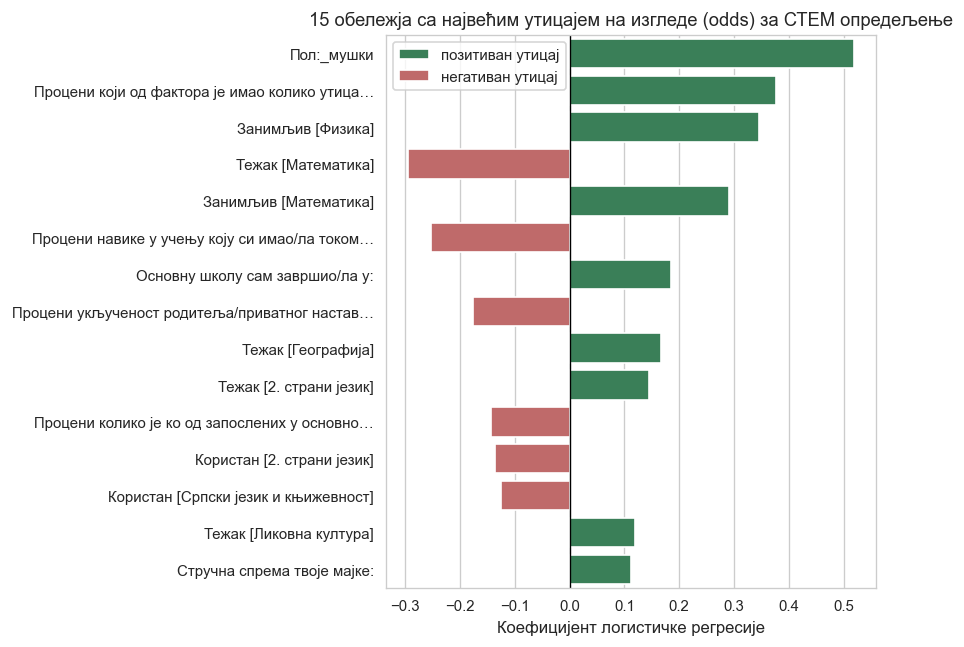

In [117]:
def izabrana_obelezja(pipe):
    """Називи обележја која је SelectKBest задржао у обученом низу корака (без префикса корака)."""
    imena = pipe.named_steps['pretprocesor'].get_feature_names_out()
    maska = pipe.named_steps['selekcija'].get_support()
    return [n.split('__', 1)[1] for n, keep in zip(imena, maska) if keep]


coef_df = pd.DataFrame({
    'обележје': izabrana_obelezja(logreg_best),
    'коефицијент': logreg_best.named_steps['model'].coef_[0],
})
coef_df['odds_ratio'] = np.exp(coef_df['коефицијент'])
coef_df['абс_коефицијент'] = coef_df['коефицијент'].abs()
coef_df['бинарно'] = coef_df['обележје'].isin(binarne_kolone)

broj_nula = (coef_df['коефицијент'] == 0).sum()
print(f'Изабрано обележја (k): {len(coef_df)}')
print(f'Коефицијенти искључени L1 регуларизацијом (тачно нула): {broj_nula} од {len(coef_df)}')

top15_koef = coef_df.sort_values('абс_коефицијент', ascending=False).head(15).drop(columns='абс_коефицијент')
print('\n15 обележја са највећим (апсолутним) утицајем на изгледе (odds) за СТЕМ:')
print(top15_koef.to_string(index=False))

def skrati_naziv(naziv, duzina=45):
    return naziv if len(naziv) <= duzina else naziv[:duzina - 1] + '…'

plot_df = top15_koef.copy()
plot_df['обележје_кратко'] = plot_df['обележје'].apply(skrati_naziv)
plot_df['смер'] = plot_df['коефицијент'].apply(lambda v: 'позитиван утицај' if v > 0 else 'негативан утицај')

plt.figure(figsize=(7.5, 5.5))
sns.barplot(
    data=plot_df, x='коефицијент', y='обележје_кратко', hue='смер', dodge=False,
    palette={'позитиван утицај': 'seagreen', 'негативан утицај': 'indianred'},
)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Коефицијент логистичке регресије')
plt.ylabel('')
plt.title('15 обележја са највећим утицајем на изгледе (odds) за СТЕМ опредељење')
plt.legend(title='')
plt.tight_layout()
plt.show()

**Закључак:** L1 регуларизација (изабрана претрагом у одељку 5.4.1) свела је 53 од 90 изабраних коефицијената тачно на нулу — преосталих 37 обележја стварно доприноси предикцији.

Тумачење odds ratio-а зависи од типа обележја: **нумеричка** обележја се скалирају унутар низа корака (одељак 4.7), па се њихов odds ratio односи на пораст од једне стандардне девијације; **бинарна/индикаторска** обележја се не скалирају, па се њихов odds ratio односи директно на прелазак из једне категорије у другу (0 → 1).

Најизраженији позитиван утицај на изгледе (odds) за СТЕМ опредељење има пол (`Пол:_мушки`, odds ratio ≈1.68 — мушки пол је повезан са ~68% већим изгледима за СТЕМ у односу на женски, у складу са χ² тестом из одељка 3.5), затим склоност ка одређеној групи предмета као фактор одлуке о упису (odds ratio ≈1.46) и занимљивост физике (odds ratio ≈1.41). Најизраженији негативан утицај има перципирана тежина математике (odds ratio ≈0.75 — виша пријављена тежина повезана је са мањим изгледима за СТЕМ), у складу са негативном корелацијом из одељка 2.5. Резултати су у великој мери конзистентни са статистичким тестовима (3. поглавље) и корелационом матрицом (2.5), што повећава поузданост закључака.

## 7.2. Feature importance (Random Forest, XGBoost)

Упоређујемо меру значаја обележја (feature importance) код Random Forest и XGBoost модела, засновану на смањењу нечистоће приликом дељења чворова.

Преклапање топ 10 обележја по Random Forest и XGBoost значају: 7/10
['Занимљив [Математика]', 'Занимљив [Физика]', 'Користан [Математика]', 'Користан [Физика]', 'Пол:_мушки', 'Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Склоност ка одређеној групи предмета]', 'Тежак [Математика]']

Топ 15 обележја по просечном рангу значаја (RF + XGBoost):
                                                                                                                                         обележје  значај_RF  значај_XGB  просечан_ранг
                                                                                                                                Занимљив [Физика]   0.045839    0.060404            1.0
                                                                                                                            Занимљив [Математика]   0.041707    0.059692            2.0
        Процени који од фактора је имао колико ути

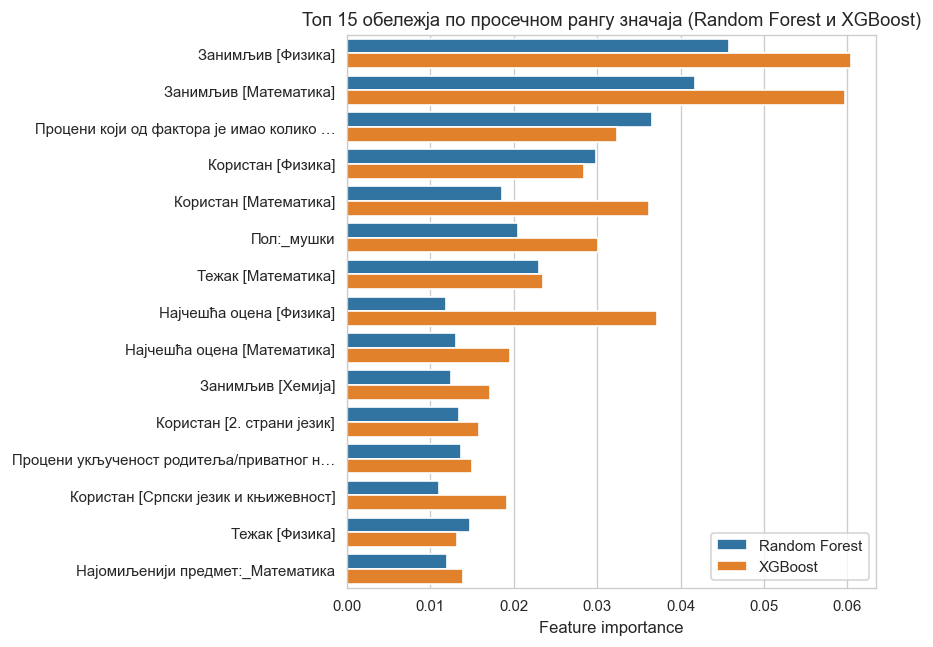

In [118]:
rf_imp = pd.DataFrame({
    'обележје': izabrana_obelezja(rf_best),
    'значај_RF': rf_best.named_steps['model'].feature_importances_,
})
xgb_imp = pd.DataFrame({
    'обележје': izabrana_obelezja(xgb_best),
    'значај_XGB': xgb_best.named_steps['model'].feature_importances_,
})

combined_imp = rf_imp.merge(xgb_imp, on='обележје')
combined_imp['просечан_ранг'] = (
    combined_imp['значај_RF'].rank(ascending=False) + combined_imp['значај_XGB'].rank(ascending=False)
) / 2

top_rf_10 = set(rf_imp.sort_values('значај_RF', ascending=False).head(10)['обележје'])
top_xgb_10 = set(xgb_imp.sort_values('значај_XGB', ascending=False).head(10)['обележје'])
preklapanje = top_rf_10 & top_xgb_10
print(f'Преклапање топ 10 обележја по Random Forest и XGBoost значају: {len(preklapanje)}/10')
print(sorted(preklapanje))

top15_imp = combined_imp.sort_values('просечан_ранг').head(15)
print('\nТоп 15 обележја по просечном рангу значаја (RF + XGBoost):')
print(top15_imp.to_string(index=False))

def skrati_naziv(naziv, duzina=40):
    return naziv if len(naziv) <= duzina else naziv[:duzina - 1] + '…'

plot_data = top15_imp.copy()
plot_data['обележје_кратко'] = plot_data['обележје'].apply(skrati_naziv)
plot_melt = plot_data.melt(
    id_vars='обележје_кратко', value_vars=['значај_RF', 'значај_XGB'],
    var_name='модел', value_name='значај',
)
plot_melt['модел'] = plot_melt['модел'].map({'значај_RF': 'Random Forest', 'значај_XGB': 'XGBoost'})

plt.figure(figsize=(7.5, 5.5))
sns.barplot(data=plot_melt, x='значај', y='обележје_кратко', hue='модел')
plt.xlabel('Feature importance')
plt.ylabel('')
plt.title('Топ 15 обележја по просечном рангу значаја (Random Forest и XGBoost)')
plt.legend(title='')
plt.tight_layout()
plt.show()

**Закључак:** топ 10 обележја по значају код Random Forest и XGBoost модела преклапа се у 7 од 10 случајева — оба модела независно препознају занимљивост физике и математике, склоност ка одређеној групи предмета, корисност физике/математике, пол и перципирану тежину математике као најутицајнија обележја. Ово је у складу са одељком 7.1 (odds ratio), где су иста обележја (`Пол:_мушки`, `Занимљив [Физика]`, склоност ка групи предмета, `Тежак [Математика]`) имала највећи утицај — три независне методе интерпретације конзистентно указују на исти скуп најзначајнијих предиктора, што знатно повећава поузданост налаза. Најчешћа оцена из физике и математике јаче се издваја код XGBoost-а него код Random Forest-а, вероватно због разлика у начину на који два алгоритма распоређују значај међу међусобно корелисаним обележјима (оцена и занимљивост тих предмета су умерено повезане, одељак 2.5), а не зато што један модел погрешно процењује стваран утицај.

## 7.3. SHAP анализа

Применом SHAP анализе на Random Forest модел (носилац анализе интерпретабилности, види увод поглавља) рачунамо допринос сваког обележја појединачним предикцијама и приказујемо укупан значај кроз summary plot. SHAP вредности рачунамо на трансформисаном тест скупу (после скалирања и селекције обележја у низу корака).

Топ 15 обележја по просечном апсолутном SHAP доприносу предикцији СТЕМ:
                                                                                                                                                          обележје  просечан_|SHAP|
                                                                                                                                                 Занимљив [Физика]         0.036633
                         Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Склоност ка одређеној групи предмета]         0.033448
                                                                                                                                             Занимљив [Математика]         0.031525
                                                                                                                                                 Користан [Физика]         0.025800
                            

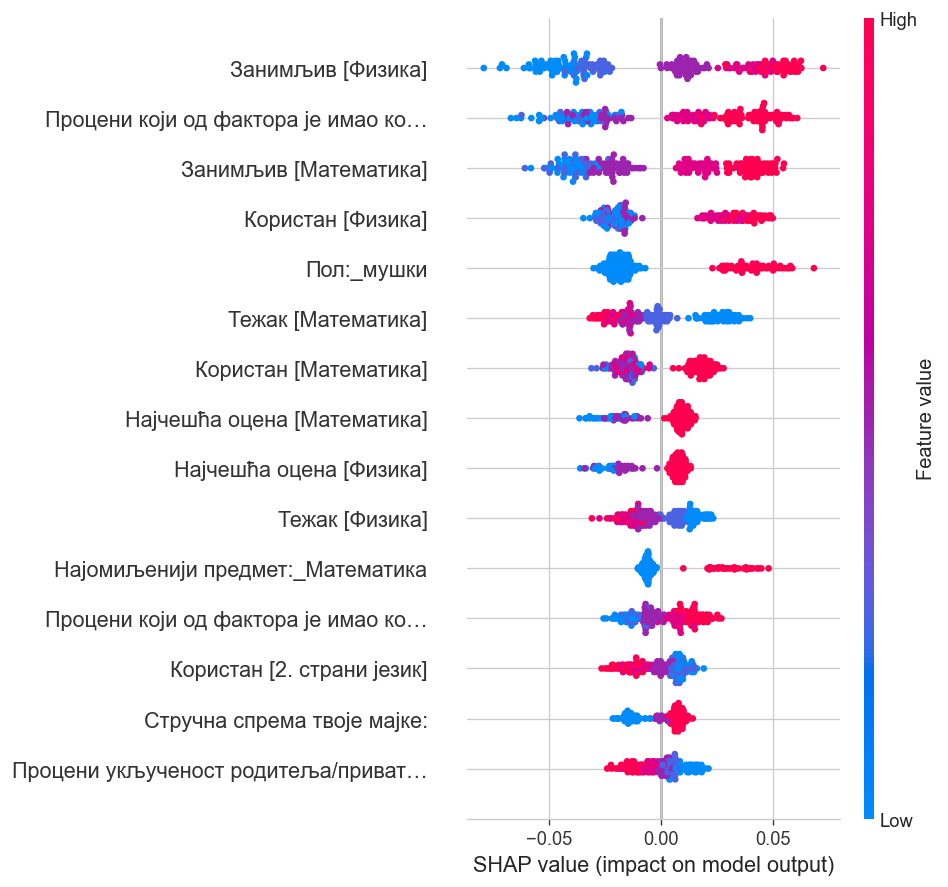

In [119]:
import warnings
from tqdm import TqdmWarning
# shap повлачи tqdm, који у Jupyter режиму тражи ipywidgets progress-bar (није укључен) —
# упозорење је чисто козметичко и не тиче се SHAP резултата.
warnings.filterwarnings('ignore', category=TqdmWarning)

import shap

feat_rf = izabrana_obelezja(rf_best)
X_test_trans = rf_best[:-1].transform(X_test)  # низ корака без завршног модела

explainer = shap.TreeExplainer(rf_best.named_steps['model'])
shap_values = explainer.shap_values(X_test_trans)
shap_values_stem = shap_values[:, :, 1]  # доприноси предикцији СТЕМ (класа 1)

prosecan_abs_shap = np.abs(shap_values_stem).mean(axis=0)
shap_imp = pd.DataFrame({
    'обележје': feat_rf,
    'просечан_|SHAP|': prosecan_abs_shap,
}).sort_values('просечан_|SHAP|', ascending=False)
print('Топ 15 обележја по просечном апсолутном SHAP доприносу предикцији СТЕМ:')
print(shap_imp.head(15).to_string(index=False))

def skrati_naziv(naziv, duzina=35):
    return naziv if len(naziv) <= duzina else naziv[:duzina - 1] + '…'

kratki_nazivi = [skrati_naziv(n) for n in feat_rf]

plt.figure(figsize=(7.5, 6))
shap.summary_plot(shap_values_stem, X_test_trans, feature_names=kratki_nazivi, show=False, max_display=15)
plt.tight_layout()
plt.show()

**Закључак:** SHAP анализа (`TreeExplainer` на Random Forest моделу, доприноси предикцији СТЕМ класе) потврђује исти скуп најутицајнијих обележја као и одељци 7.1 и 7.2: прва три места по просечном апсолутном SHAP доприносу заузимају `Занимљив [Физика]`, склоност ка одређеној групи предмета и `Занимљив [Математика]`, а за њима следе `Користан [Физика]` и `Пол:_мушки`.

Summary plot додатно показује и **смер** утицаја сваке вредности обележја: високе (црвене) вредности занимљивости физике и математике доследно повлаче позитиван SHAP допринос (веће изгледе за СТЕМ), док високе вредности перципиране тежине математике повлаче негативан допринос — у складу са предзнаком коефицијената из 7.1. Код обележја `Пол:_мушки` (бинарно, 0/1) јасно се виде две одвојене групе тачака: висока вредност (мушки пол) готово увек носи позитиван SHAP допринос, ниска вредност (женски пол) готово увек негативан — у складу са родном разликом у СТЕМ опредељењу (одељак 3.5). Конзистентност три независне методе интерпретације (коефицијенти, feature importance, SHAP) додатно потврђује поузданост налаза.

## 7.4. Који фактори највише утичу на СТЕМ афинитет — идентификација најзначајнијег предиктора

Упоређујемо најзначајнија обележја идентификована у 7.1–7.3 како бисмо издвојили најдоследнији и најзначајнији предиктор СТЕМ опредељења.

Топ 10 обележја по просечном рангу кроз три методе интерпретације (7.1, 7.2, 7.3):
                                                                                                                                         обележје  ранг_коеф  ранг_ансамбл  ранг_SHAP  просечан_ранг_укупно
                                                                                                                                Занимљив [Физика]        3.0           1.0        1.0              1.666667
        Процени који од фактора је имао колико утицаја на твоју одлуку за упис и похађање изабраног смера. [Склоност ка одређеној групи предмета]        2.0           4.0        2.0              2.666667
                                                                                                                            Занимљив [Математика]        5.0           2.0        3.0              3.333333
                                                                                                     

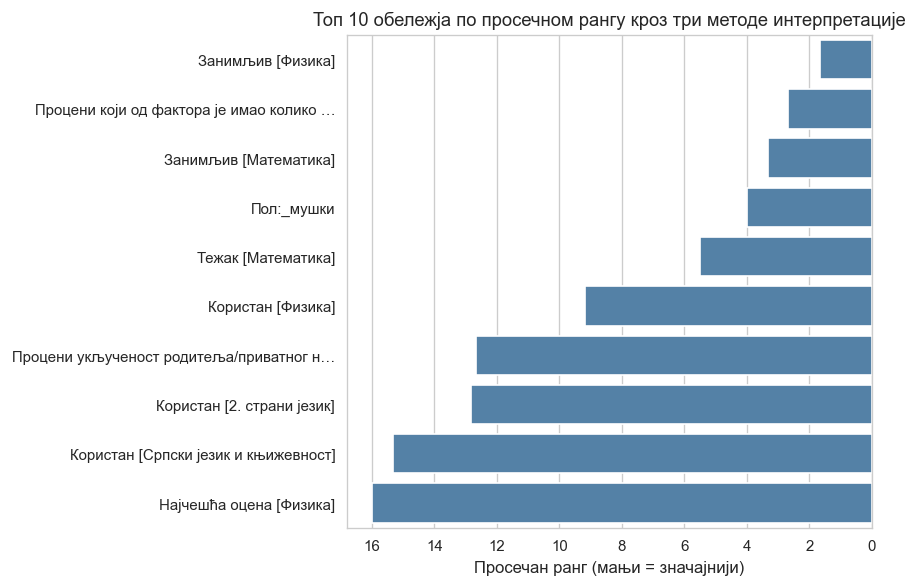

In [120]:
rank_71 = coef_df[['обележје', 'абс_коефицијент']].copy()
rank_71['ранг_коеф'] = rank_71['абс_коефицијент'].rank(ascending=False)

rank_72 = combined_imp[['обележје', 'просечан_ранг']].rename(columns={'просечан_ранг': 'ранг_ансамбл'})

rank_73 = shap_imp.copy()
rank_73['ранг_SHAP'] = rank_73['просечан_|SHAP|'].rank(ascending=False)

sinteza = (
    rank_71[['обележје', 'ранг_коеф']]
    .merge(rank_72, on='обележје')
    .merge(rank_73[['обележје', 'ранг_SHAP']], on='обележје')
)
sinteza['просечан_ранг_укупно'] = sinteza[['ранг_коеф', 'ранг_ансамбл', 'ранг_SHAP']].mean(axis=1)
sinteza = sinteza.sort_values('просечан_ранг_укупно')

print('Топ 10 обележја по просечном рангу кроз три методе интерпретације (7.1, 7.2, 7.3):')
print(sinteza.head(10).to_string(index=False))

def skrati_naziv(naziv, duzina=40):
    return naziv if len(naziv) <= duzina else naziv[:duzina - 1] + '…'

top10_sinteza = sinteza.head(10).copy()
top10_sinteza['обележје_кратко'] = top10_sinteza['обележје'].apply(skrati_naziv)

plt.figure(figsize=(7.5, 5))
sns.barplot(data=top10_sinteza, x='просечан_ранг_укупно', y='обележје_кратко', color='steelblue')
plt.xlabel('Просечан ранг (мањи = значајнији)')
plt.ylabel('')
plt.title('Топ 10 обележја по просечном рангу кроз три методе интерпретације')
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

**Закључак:** синтеза три независне методе интерпретације (коефицијенти логистичке регресије, feature importance код Random Forest и XGBoost, и SHAP анализа) даје конзистентан одговор: **`Занимљив [Физика]`** (перципирана занимљивост физике у основној школи) има најнижи просечан ранг (≈1.7) кроз све три методе и издваја се као појединачно најзначајнији предиктор СТЕМ опредељења. Одмах иза њега следе фактор „склоност ка одређеној групи предмета“ (просечан ранг ≈2.7), занимљивост математике (≈3.3) и пол ученика (≈4.0), а затим перципирана тежина математике.

Важно је нагласити да ниједан појединачни предиктор није доминантан у апсолутном смислу (видети одељак 6.5) — реч је о комбинацији више умерено јаких обележја везаних за интересовање и став према СТЕМ предметима, а не о једном пресудном фактору. Ово је у складу и са статистичким тестовима из 3. поглавља, где су се занимљивост, корисност и перципирана тежина СТЕМ предмета показали као доследно значајни показатељи СТЕМ опредељења.

# 8. Анализа правичности и робусности модела

У овом поглављу испитујемо да ли истренирани модели показују различите перформансе према полу ученика, да ли постоји системска пристрасност у предикцијама, као и колико су резултати осетљиви на уклањање најзначајнијих предиктора.

## 8.1. Перформансе модела по полу

Рачунамо метрике евалуације одвојено за ученике мушког и женског пола како бисмо утврдили да ли модел подједнако добро класификује обе групе.

In [121]:
muski_mask = X_test['Пол:_мушки'].values
zenski_mask = ~muski_mask

def bazna_stopa(y):
    """Тачност тривијалног модела (увек већинска класа) у датој подгрупи."""
    p = y.mean()
    return max(p, 1 - p)

for naziv, mask in [('Мушки', muski_mask), ('Женски', zenski_mask)]:
    ys = y_test[mask]
    print(f'{naziv}: n={mask.sum()}, СТЕМ удео {ys.mean():.3f}, базна стопа (већинска класа) {bazna_stopa(ys):.3f}')

def metrike_po_grupi(y_true, y_pred, y_proba):
    acc = accuracy_score(y_true, y_pred)
    return {
        'Accuracy': acc,
        'Изнад базне': acc - bazna_stopa(y_true),
        'F1 (weighted)': f1_score(y_true, y_pred, average='weighted'),
        'ROC-AUC': roc_auc_score(y_true, y_proba),
    }

modeli_svi = {
    'Logistic Regression': logreg_best,
    'KNN': knn_best,
    'SVM': svm_best,
    'Random Forest': rf_best,
    'XGBoost': xgb_best,
}

rezultati_po_polu = {}
for naziv, model in modeli_svi.items():
    for pol_naziv, mask in [('Мушки', muski_mask), ('Женски', zenski_mask)]:
        X_sub = X_test[mask]
        y_sub = y_test[mask]
        y_pred = model.predict(X_sub)
        y_proba = model.predict_proba(X_sub)[:, 1]
        rezultati_po_polu[(naziv, pol_naziv)] = metrike_po_grupi(y_sub, y_pred, y_proba)

tabela_po_polu = pd.DataFrame(rezultati_po_polu).T.round(3)
tabela_po_polu.index.names = ['Модел', 'Пол']
print('\nМетрике по полу (Изнад базне = Accuracy − тачност тривијалног модела у тој подгрупи):')
print(tabela_po_polu)

Мушки: n=64, СТЕМ удео 0.609, базна стопа (већинска класа) 0.609
Женски: n=143, СТЕМ удео 0.329, базна стопа (већинска класа) 0.671

Метрике по полу (Изнад базне = Accuracy − тачност тривијалног модела у тој подгрупи):
                            Accuracy  Изнад базне  F1 (weighted)  ROC-AUC
Модел               Пол                                                  
Logistic Regression Мушки      0.750        0.141          0.752    0.773
                    Женски     0.720        0.049          0.722    0.779
KNN                 Мушки      0.656        0.047          0.660    0.708
                    Женски     0.713        0.042          0.717    0.781
SVM                 Мушки      0.766        0.156          0.768    0.779
                    Женски     0.797        0.126          0.797    0.799
Random Forest       Мушки      0.688        0.078          0.691    0.779
                    Женски     0.783        0.112          0.775    0.793
XGBoost             Мушки      0.734     

**Закључак:** тест скуп садржи 64 ученика мушког пола (СТЕМ удео 60.9%, базна стопа 0.609) и 143 ученице (СТЕМ удео 32.9%, базна стопа 0.671) — велика разлика у базном СТЕМ уделу директно одражава родну повезаност из χ² теста (одељак 3.5).

Гола тачност по полу је обмањујућа: женска подгрупа има већу базну стопу (тривијални модел који свима предвиђа НЕ-СТЕМ погодио би 67.1% девојчица наспрам 60.9% дечака), па виша тачност за девојчице не значи нужно да је модел бољи за њих. Зато поредимо **тачност изнад базне стопе подгрупе**. По том мерилу нема доследне разлике на штету једног пола: SVM, логистичка регресија и XGBoost су изнад базне стопе више за мушку подгрупу (нпр. SVM +0.16 наспрам +0.13), Random Forest нешто више за женску (+0.11 наспрам +0.08), а KNN приближно једнако (+0.05 / +0.04). Мања мушка подгрупа (64 наспрам 143) чини процене нестабилнијим. Системску пристрасност детаљније испитујемо у наредном одељку.

## 8.2. Анализа потенцијалног bias-а

Упоређујемо стопу позитивне предикције (СТЕМ) и грешке по типу (FPR/FNR) између полова ради процене потенцијалне пристрасности модела.

Село у тест скупу: 17 (СТЕМ удео 0.176, 3 стварних СТЕМ случајева)
Град/варошица у тест скупу: 190 (СТЕМ удео 0.437)

Метрике потенцијалне пристрасности (Random Forest) по групама:
               Стопа позитивне предикције    FPR    FNR      n
Мушки                               0.516  0.280  0.333   64.0
Женски                              0.252  0.104  0.447  143.0
Село                                0.118  0.143  1.000   17.0
Град/варошица                       0.353  0.140  0.373  190.0


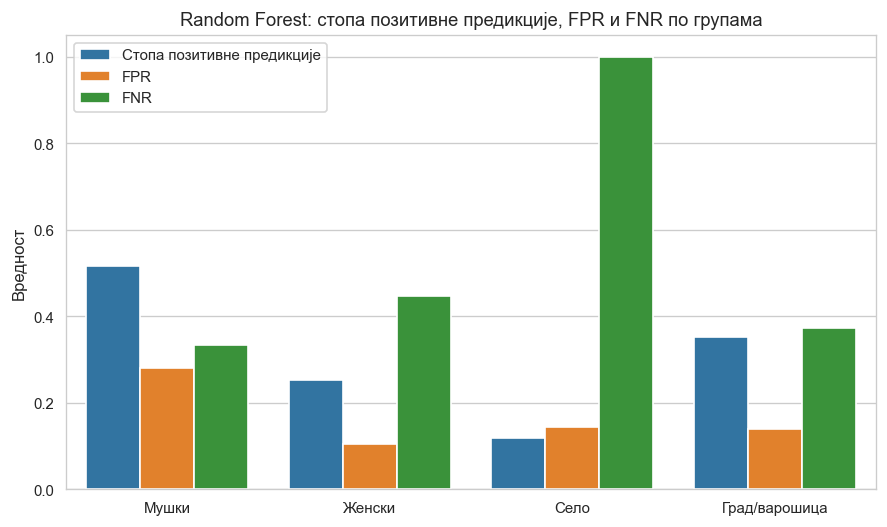

In [122]:
selo_mask = (X_test['Одрастао/ла сам у:'] == 1).values
grad_mask = ~selo_mask
print(f"Село у тест скупу: {selo_mask.sum()} (СТЕМ удео {y_test[selo_mask].mean():.3f}, {y_test[selo_mask].sum()} стварних СТЕМ случајева)")
print(f"Град/варошица у тест скупу: {grad_mask.sum()} (СТЕМ удео {y_test[grad_mask].mean():.3f})")

def bias_metrike(model, X_te, y_true, mask):
    X_sub = X_te[mask]
    y_sub = y_true[mask].values
    y_pred = model.predict(X_sub)
    stopa_pozitivne = y_pred.mean()
    stvarno_negativni = y_sub == 0
    stvarno_pozitivni = y_sub == 1
    fpr = (y_pred[stvarno_negativni] == 1).mean() if stvarno_negativni.sum() > 0 else float('nan')
    fnr = (y_pred[stvarno_pozitivni] == 0).mean() if stvarno_pozitivni.sum() > 0 else float('nan')
    return {'Стопа позитивне предикције': stopa_pozitivne, 'FPR': fpr, 'FNR': fnr, 'n': int(mask.sum())}

grupe = {
    'Мушки': muski_mask, 'Женски': zenski_mask,
    'Село': selo_mask, 'Град/варошица': grad_mask,
}
rez_bias = {naziv: bias_metrike(rf_best, X_test, y_test, mask) for naziv, mask in grupe.items()}
tabela_bias = pd.DataFrame(rez_bias).T.round(3)
print("\nМетрике потенцијалне пристрасности (Random Forest) по групама:")
print(tabela_bias)

plot_bias = tabela_bias.reset_index().rename(columns={'index': 'Група'}).melt(
    id_vars='Група', value_vars=['Стопа позитивне предикције', 'FPR', 'FNR'],
    var_name='метрика', value_name='вредност',
)
plt.figure(figsize=(7.5, 4.5))
sns.barplot(data=plot_bias, x='Група', y='вредност', hue='метрика')
plt.ylabel('Вредност')
plt.xlabel('')
plt.title('Random Forest: стопа позитивне предикције, FPR и FNR по групама')
plt.legend(title='')
plt.tight_layout()
plt.show()

**Закључак:** пристрасност Random Forest модела процењујемо кроз стопу позитивне предикције (удео предвиђених СТЕМ), FPR (лажно позитивних међу стварно НЕ-СТЕМ) и FNR (лажно негативних међу стварно СТЕМ).

**По полу:** модел предвиђа СТЕМ за 51.6% мушких наспрам 25.2% женских ученика — разлика која великим делом одражава стварну разлику у базном уделу (60.9% наспрам 32.9%, одељак 8.1), не нужно пристрасност модела. FNR је виши код девојчица (44.7% наспрам 33.3%) — модел чешће пропушта стварне СТЕМ случајеве међу девојчицама.

**По месту одрастања** налаз је упадљивији: стопа позитивне предикције за село 11.8%, а FNR 100% — модел није препознао ниједног од само **3** стварна СТЕМ ученика из села у тест скупу. Овако екстремна вредност директно произилази из изразито малог броја позитивних случајева и **није поуздана процена**, али је у складу са ниским базним СТЕМ уделом за село (17.6%, одељак 3.6) и указује да модел може системски потцењивати СТЕМ афинитет ученика из мањих средина.

Разлике међу групама делом потичу из стварних, документованих разлика у базним стопама, а делом из малог узорка за поједине подгрупе (село — свега 17 ученика у тест скупу). За практичну примену била би неопходна анализа на већем и уравнотеженијем узорку.

## 8.3. Анализа робусности (уклањање кључних предиктора)

Проверавамо колико се модел ослања на појединачна обележја, кроз две поновне обуке Random Forest модела (цео низ корака) на тренинг скупу:

1. **без појединачно најзначајнијег предиктора** (`Занимљив [Физика]`, одељак 7.4);
2. **без целог блока „фактори одлуке о упису"** (7 колона: породица, вршњаци, наставник, медији, склоност ка групи предмета, проходност на факултет, интересовање за занимање). Та питања се постављају ученику *после* уписа и траже да ретроспективно образложи баш ту одлуку коју модел предвиђа — делом су квазициркуларна. Уклањањем целог блока остају само „претходни" фактори: оцене, доживљај предмета у основној школи и социодемографске карактеристике.

Блок „фактори одлуке о упису": 7 колона

Поређење перформанси Random Forest модела:
                                             Accuracy  F1 (weighted)  ROC-AUC
Све обележја                                    0.754          0.748    0.812
Без „Занимљив [Физика]"                         0.758          0.754    0.817
Без блока „фактори одлуке о упису" (7 кол.)     0.710          0.706    0.756

Прво обележје по значају без блока „фактори одлуке": Занимљив [Физика]


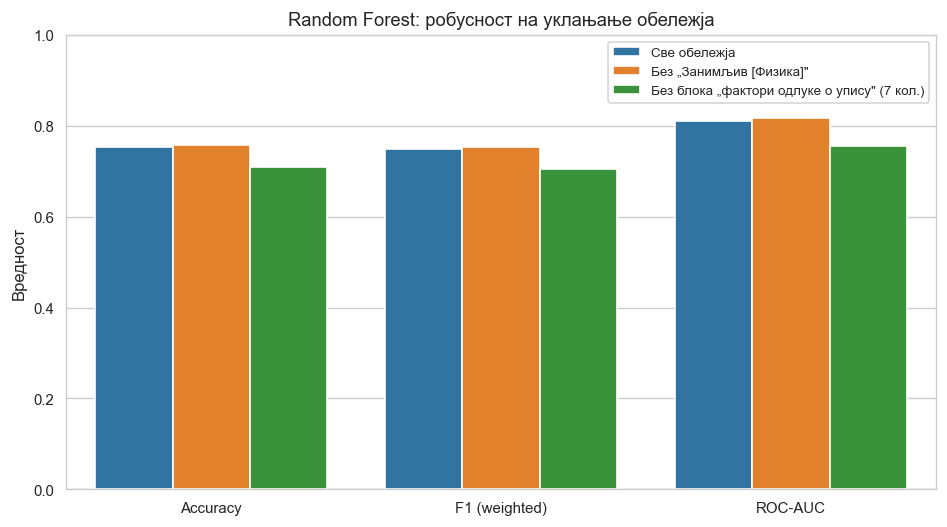

In [123]:
from sklearn.ensemble import RandomForestClassifier

grid_rf_robust = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5],
    'selekcija__k': [10, 30, 50, 70, 90, 'all'],
}

def rf_bez_kolona(kolone_za_izbacivanje):
    """Поново подешава Random Forest (цео низ корака) на тренинг скупу без задатих колона."""
    Xtr = X_train.drop(columns=kolone_za_izbacivanje)
    Xte = X_test.drop(columns=kolone_za_izbacivanje)
    num = [c for c in numericke_za_skaliranje if c in Xtr.columns]
    binr = [c for c in binarne_kolone if c in Xtr.columns]
    gs = GridSearchCV(
        napravi_pipeline(RandomForestClassifier(random_state=42), numericke=num, binarne=binr),
        grid_rf_robust, scoring='f1_weighted', cv=skf, n_jobs=-1,
    )
    gs.fit(Xtr, y_train)
    est = gs.best_estimator_
    yp, ypr = est.predict(Xte), est.predict_proba(Xte)[:, 1]
    metrike = {
        'Accuracy': accuracy_score(y_test, yp),
        'F1 (weighted)': f1_score(y_test, yp, average='weighted'),
        'ROC-AUC': roc_auc_score(y_test, ypr),
    }
    return metrike, est

# полазни Random Forest из 6. поглавља
rez_svi = {
    'Accuracy': accuracy_score(y_test, rf_best.predict(X_test)),
    'F1 (weighted)': f1_score(y_test, rf_best.predict(X_test), average='weighted'),
    'ROC-AUC': roc_auc_score(y_test, rf_best.predict_proba(X_test)[:, 1]),
}

# (а) без појединачно најзначајнијег предиктора (одељак 7.4)
najznacajniji_prediktor = 'Занимљив [Физика]'
rez_bez_top, _ = rf_bez_kolona([najznacajniji_prediktor])

# (б) без целог блока „фактори одлуке о упису" — та питања се постављају ПОСЛЕ уписа
#     и траже од ученика да ретроспективно образложи баш ту одлуку коју модел предвиђа
faktori_odluke = [c for c in X_train.columns
                  if c.startswith('Процени који од фактора је имао колико утицаја')]
print(f'Блок „фактори одлуке о упису": {len(faktori_odluke)} колона')
rez_bez_bloka, est_bez_bloka = rf_bez_kolona(faktori_odluke)

poredjenje = pd.DataFrame({
    'Све обележја': rez_svi,
    f'Без „{najznacajniji_prediktor}"': rez_bez_top,
    'Без блока „фактори одлуке о упису" (7 кол.)': rez_bez_bloka,
}).T
print('\nПоређење перформанси Random Forest модела:')
print(poredjenje.round(3))

feat_bb = izabrana_obelezja(est_bez_bloka)
novi_znacaj = pd.DataFrame({
    'обележје': feat_bb, 'значај': est_bez_bloka.named_steps['model'].feature_importances_,
}).sort_values('значај', ascending=False)
print('\nПрво обележје по значају без блока „фактори одлуке":', novi_znacaj.iloc[0]['обележје'])

plot_pored = poredjenje.reset_index().rename(columns={'index': 'Варијанта'}).melt(
    id_vars='Варијанта', var_name='метрика', value_name='вредност'
)
plt.figure(figsize=(8, 4.5))
sns.barplot(data=plot_pored, x='метрика', y='вредност', hue='Варијанта')
plt.ylabel('Вредност')
plt.xlabel('')
plt.ylim(0, 1)
plt.title('Random Forest: робусност на уклањање обележја')
plt.legend(title='', fontsize=8)
plt.tight_layout()
plt.show()

**Закључак:** уклањање појединачно најзначајнијег предиктора (`Занимљив [Физика]`) **готово да не мења перформансе** — Accuracy 0.754 → 0.758, ROC-AUC 0.812 → 0.817. Сигнал није концентрисан у једном обележју: модел преусмерава ослањање на најближе преостале сродне показатеље (занимљивост математике, корисност физике), с којима је уклоњено обележје умерено до снажно корелисано (одељак 2.5).

Уклањање целог блока „фактори одлуке о упису" (7 колона) даје јаснији пад — Accuracy 0.754 → 0.710, F1 (weighted) 0.748 → 0.706, ROC-AUC 0.812 → 0.756 (≈4–6 процентних поена). Дакле модел се делом ослања на тај ретроспективни, делом квазициркуларни блок. Ипак, и без њега — само на основу „претходних" фактора (оцене, доживљај предмета у основној школи, социодемографија) — модел остаје знатно изнад baseline-а (0.710 наспрам 0.585); предиктивна вредност постоји и у чисто претходним обележјима, а најзначајније међу њима је опет занимљивост физике у основној школи.

# 9. Закључак

Опредељење ученика ка СТЕМ смеровима показало се као резултат комбинације више међусобно повезаних фактора, а не једног пресудног узрока. Занимљивост физике и математике, склоност ка одређеној групи предмета приликом уписа и пол ученика конзистентно су се издвојили као најутицајнији предиктори кроз три независне методе интерпретације (коефицијенти логистичке регресије, feature importance и SHAP анализа, поглавље 7), што знатно повећава поузданост ових налаза.

Пет истренираних модела показало се практично неразликивим по унакрсној валидацији (CV F1 у распону 0.745–0.754); на независном тест скупу SVM води по тачности, а Random Forest по ROC-AUC, али су разлике међу бољим моделима унутар граница узорачке грешке (поглавље 6). Сви модели значајно надмашују референтни (baseline) модел, што потврђује да се СТЕМ опредељење може предвидети са задовољавајућом тачношћу на основу лако доступних анкетних података. Анализа робусности (одељак 8.3) показала је да уклањање појединачно најзначајнијег предиктора готово не мења перформансе, док уклањање целог блока ретроспективних питања о разлозима уписа доноси умерен пад — предиктивни сигнал је расподељен, али се делом ослања на факторе које ученици наводе тек после доношења одлуке.

Анализа правичности (одељци 8.1–8.2) показала је да, када се тачност пореди са базном стопом сваке подгрупе, нема доследне разлике у квалитету предикције по полу; уочене разлике у стопама позитивне предикције углавном одражавају стварне разлике у базним стопама. Налази за ученике из руралних средина ограничени су малим узорком. Ово указује на потребу за опрезном применом оваквих модела у пракси — пре свега као алата за препознавање образаца на нивоу популације, а не за одлуке о појединачним ученицима.